# cartographie de failles géologiques par apprentissage supervisé

**Objectif.** Pour chaque pixel (100 m × 100 m) de la région GeoDAWN (Nevada / Californie), prédire la probabilité qu'il appartienne à une **faille**, à partir de 19 cartes géophysiques (magnétisme, gravimétrie, déformation GPS, sismicité, topographie, conductivité).

| Élément | Contenu |
|---|---|
| Cadre | classification binaire **supervisée** de pixels |
| Entrée | 19 cartes raster de **3730 lignes × 3292 colonnes** |
| Cible | masque binaire : 1 = faille, 0 = pas de faille (labels **incomplets et imprécis**) |
| Métrique | *Distance-weighted Tversky Index* |

**Plan**
1. Métrique de la compétition + métriques complémentaires
2. Découpage **spatial** en jeux d'entraînement / validation / test 
3. Feature engineering par **filtres de convolution** (scikit-image) 
4. Échantillonnage et protocole de validation ; 
5. modèles de référence ; 
6. ablation par famille de filtres 
7. **Sélection de variables** (filtre, L1, importance d'arbres, PCA) vs **sans sélection** ; clustering 
8. Comparaison des familles de modèles (bagging, boosting, MLP) ;
9.  **Optimisation des hyper-paramètres** 
10. Évaluation finale sur le **test** , post-traitement orienté DTI
11. Interprétation ; 
12. **verrous rencontrés et solutions** ; 
13. **analyse critique** ; 

## 0. Configuration

In [1]:
import os, sys, time, json, pickle, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
from scipy.signal import fftconvolve
from joblib import Parallel, delayed

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# le notebook vit dans notebook/ : on se place à la racine du projet (src/data.py utilise des chemins relatifs)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

PROC = ROOT / "data" / "processed"
PROC.mkdir(exist_ok=True)
SEED = 0
RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 9, "axes.labelsize": 8, "font.size": 8})
print("racine du projet :", ROOT)


def cached(name, fn):
    """Cache disque (pickle) pour ne pas recalculer les étapes coûteuses à chaque exécution."""
    path = PROC / f"{name}.pkl"
    if path.exists():
        return pickle.load(open(path, "rb"))
    out = fn()
    pickle.dump(out, open(path, "wb"))
    return out

racine du projet : D:\3A_IODAA\gems-challenge


## 1. Chargement des données (`src/data.py`)

Le chargement est réalisé par la fonction `load_data`: lecture raster avec `rasterio`, **remplacement des valeurs « nodata » par `NaN`** pour chaque bande.

In [ ]:
import rasterio
from src.data import load_data
import numpy as np
from os import path

def load_data(path):
    raster = rasterio.open(path)
    print(type(raster.read(1)))
    bands = [raster.read(i) for i in range(1, raster.count + 1)]
    bands = [np.where(band != raster.nodata, band, np.nan) for band in bands] # Remove nodata values from each band
    bands_array = np.array(bands)   
    return bands_array
X = load_data("data/raw/gems-geodawn-numerical-features.tif")        # (19, H, W) float32
Y_RAW = load_data("data/raw/existing_faults.tif")[0]                  # 1 faille, 0 fond, NaN = non étiqueté
with rasterio.open("data/raw/gems-geodawn-numerical-features.tif") as src:
    BAND_DESC = list(src.descriptions)
    PROFILE = src.profile
BAND_NAMES = [d.split(" - ")[0] for d in BAND_DESC]
NB, H, W = X.shape
print(f"{NB} bandes, {H} lignes x {W} colonnes = {H * W / 1e6:.1f} M pixels, CRS {PROFILE['crs']}, résolution {PROFILE['transform'][0]:.0f} m")
print(pd.Series(BAND_NAMES).to_string())

<class 'numpy.ndarray'>


load data/raw/gems-geodawn-numerical-features.tif: (19, 3730, 3292)
<class 'numpy.ndarray'>
load data/raw/existing_faults.tif: (1, 3730, 3292)
19 bandes, 3730 lignes x 3292 colonnes = 12.3 M pixels, CRS EPSG:32611, résolution 100 m
0                mag_anom
1                     rtp
2                  tmi_hg
3             geod_2ndinv
4     iso_grav_anom_slope
5                      tc
6          geod_shearrate
7         geod_dilaterate
8                  tmi_vg
9             deq_n100a15
10       iso_grav_anom_vg
11               det_elev
12          iso_grav_anom
13                    tmi
14     depth_to_base_surf
15            ieq_n100a15
16              cond_surf
17       iso_grav_anom_hg
18         det_elev_slope


Trois particularités conditionnent toute la suite :
* la zone d'étude n'occupe qu'une partie du rectangle : le reste est `NaN` (valeurs manquantes **structurelles**, non imputables) ;
* les failles sont **rares** (≈ 1 % des pixels) : classes très **déséquilibrées** ;
* quelques pixels ont une valeur manquante sur une seule bande (à imputer dans les modèles linéaires).

In [3]:
VALID = ~np.isnan(X).all(0)                                   # pixels de la zone d'étude
Y = np.where(np.isnan(Y_RAW), -1, Y_RAW).astype(np.int8)      # -1 = pixel non étiqueté (ignoré)
LABELED = VALID & (Y >= 0)
diag = pd.Series({
    "pixels de la carte": H * W,
    "pixels valides (zone d'étude)": int(VALID.sum()),
    "  part de la carte": f"{VALID.mean():.1%}",
    "pixels valides non étiquetés (ignorés)": int((VALID & (Y < 0)).sum()),
    "pixels de faille (dans la zone)": int(((Y == 1) & VALID).sum()),
    "  part des pixels étiquetés": f"{((Y == 1) & LABELED).sum() / LABELED.sum():.2%}",
    "failles hors zone (ignorées)": int(((Y == 1) & ~VALID).sum()),
    "pixels avec NaN sur 1 bande seulement": int((np.isnan(X).any(0) & VALID).sum()),
})
print(diag.to_string())

pixels de la carte                        12279160
pixels valides (zone d'étude)              5165852
  part de la carte                           42.1%
pixels valides non étiquetés (ignorés)        1540
pixels de faille (dans la zone)              60894
  part des pixels étiquetés                  1.18%
failles hors zone (ignorées)                    94
pixels avec NaN sur 1 bande seulement           12


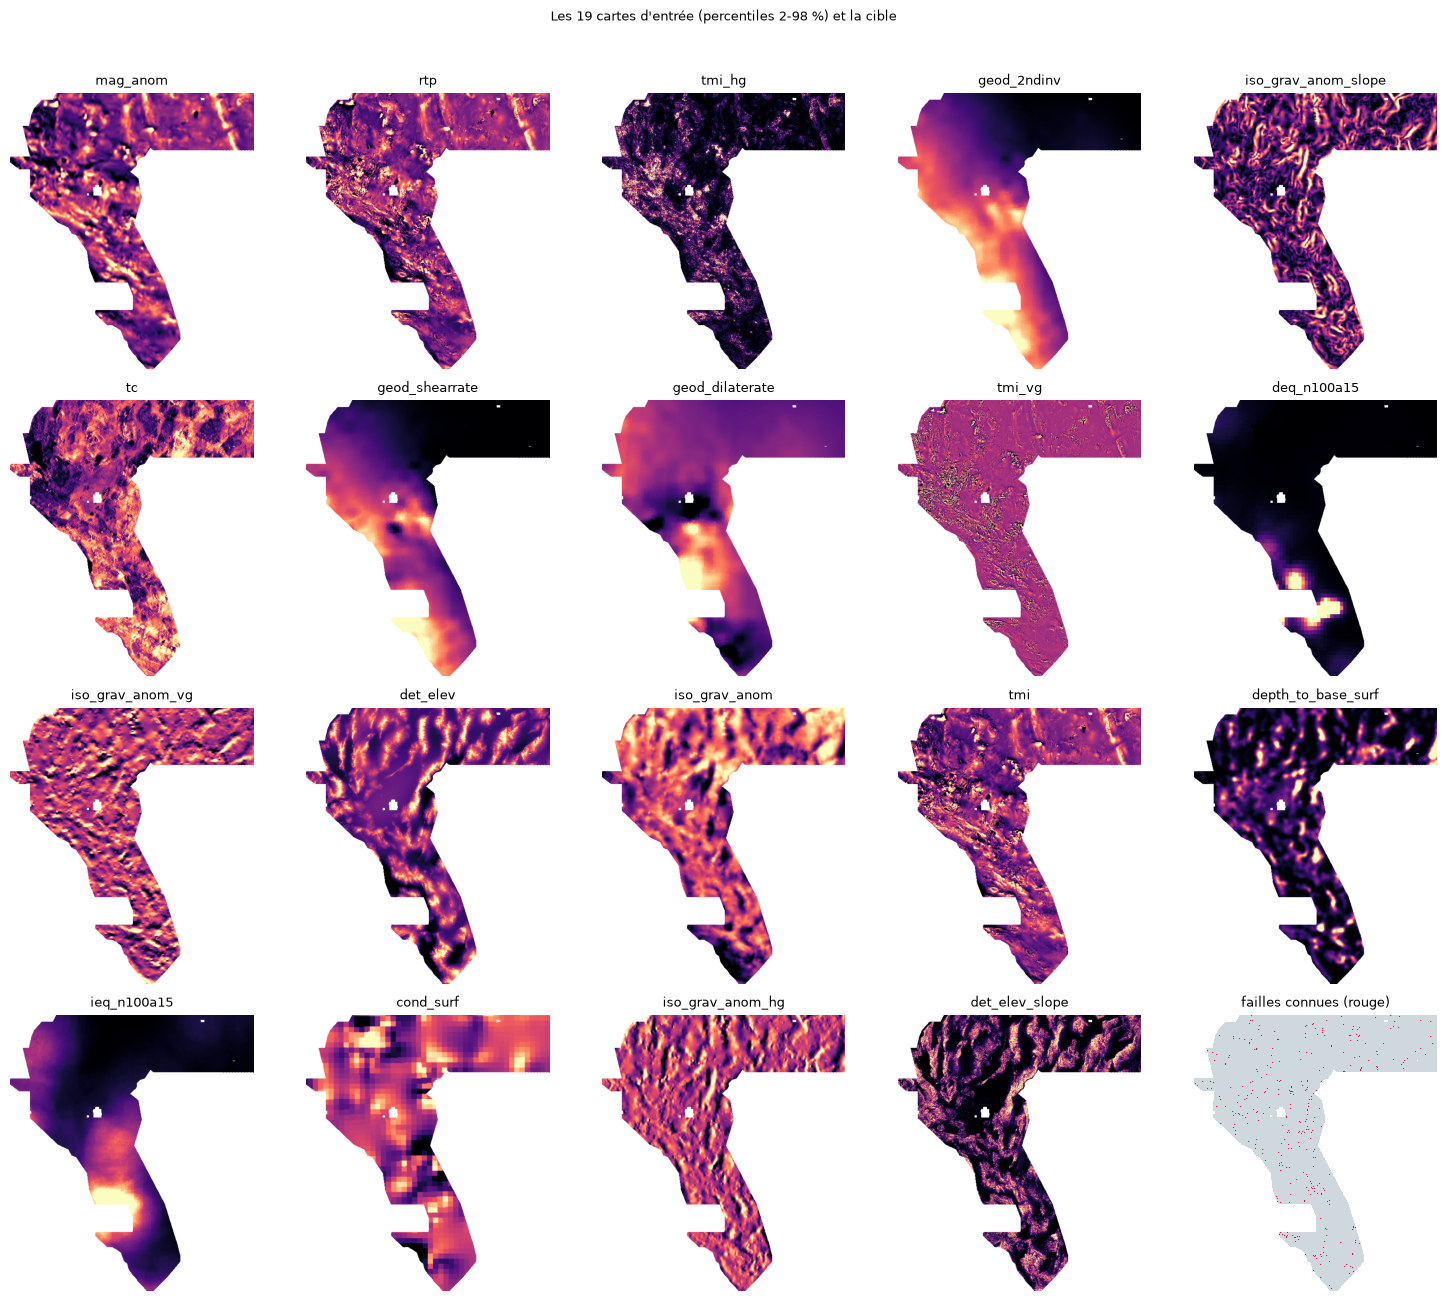

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(15, 13))
for i, ax in enumerate(axes.ravel()):
    if i < NB:
        band = X[i, ::6, ::6]
        lo, hi = np.nanpercentile(band, [2, 98])
        ax.imshow(band, cmap="magma", vmin=lo, vmax=hi)
        ax.set_title(BAND_NAMES[i])
    else:
        yy = np.where(Y[::3, ::3] == 1, 2, np.where(VALID[::3, ::3], 1, 0))
        ax.imshow(yy, cmap=ListedColormap(["white", "#cfd8dc", "crimson"]), interpolation="nearest")
        ax.set_title("failles connues (rouge)")
    ax.axis("off")
plt.suptitle("Les 19 cartes d'entrée (percentiles 2-98 %) et la cible", y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.show()

## 2. Métriques d'évaluation

### 2.1 Métrique de la compétition : *distance-weighted Tversky index* (DTI)

Soit $p(x)\in[0,1]$ la probabilité prédite, $G$ l'ensemble des pixels de faille et $k(d)=\max(1-d/R,0)$ un noyau triangulaire avec $R = 3$ pixels :

$$TP_w=\sum_{g\in G}\max_{x:\,d(x,g)\le R} p(x)\,k(d(x,g)),\quad FP_w=\sum_{x}p(x)\Big[1-\max_{g\in G}k(d(x,g))\Big],\quad FN_w=\sum_{g\in G}\Big[1-\max_{x:\,d(x,g)\le R}p(x)\,k(d(x,g))\Big]$$

$$\mathrm{DTI}=\frac{TP_w}{TP_w+\alpha\,FP_w+\beta\,FN_w},\qquad \alpha=0.2,\ \beta=0.8$$

Conséquences : (i) une prédiction à **moins de 300 m** d'une faille est partiellement récompensée ; (ii) un faux négatif coûte **4×** plus cher qu'un faux positif → la métrique favorise le **rappel** ; (iii) elle travaille sur des **probabilités** (pas de seuil) mais $FP_w$ somme $p$ sur toute la carte : un modèle qui « fuit » des petites probabilités partout est pénalisé.

**Implémentation.** $FP_w$ via une transformée en distance euclidienne (`scipy.ndimage.distance_transform_edt`) ; $TP_w$ en ne regardant que les pixels de faille et les 28 décalages $(dy,dx)$ de norme < 3.

![Metrique](gems_metric_1.png)

In [5]:
R_PX, ALPHA, BETA = 3, 0.2, 0.8
OFFSETS = [(dy, dx, 1 - np.hypot(dy, dx) / R_PX)
           for dy in range(-R_PX, R_PX + 1) for dx in range(-R_PX, R_PX + 1) if np.hypot(dy, dx) < R_PX]


class DTI:
    """Distance-weighted Tversky index sur une zone `region` (la vérité et les prédictions hors zone sont ignorées)."""

    def __init__(self, y, region, alpha=ALPHA, beta=BETA):
        self.alpha, self.beta, self.region = alpha, beta, region
        G = (y == 1) & region
        self.gy, self.gx = np.nonzero(G)
        d = ndi.distance_transform_edt(~G)
        self.w_fp = (1 - np.clip(1 - d / R_PX, 0, None)).astype(np.float32)   # 1 - max_g k(d(x,g))
        self.n_fault = len(self.gy)

    def parts(self, p):
        p = np.where(self.region, np.nan_to_num(p), 0).astype(np.float32)
        pp = np.pad(p, R_PX)
        m = np.zeros(self.n_fault, np.float32)
        for dy, dx, k in OFFSETS:
            m = np.maximum(m, pp[self.gy + R_PX + dy, self.gx + R_PX + dx] * k)
        tp = float(m.sum(dtype=np.float64))
        fn = self.n_fault - tp
        fp = float((p * self.w_fp).sum(dtype=np.float64))
        return tp, fp, fn

    def __call__(self, p):
        tp, fp, fn = self.parts(p)
        return tp / (tp + self.alpha * fp + self.beta * fn + 1e-9)


# vérification sur un cas jouet : une faille verticale, prédiction parfaite puis décalée d'un pixel
y_t = np.zeros((20, 20), np.int8); y_t[:, 10] = 1
ev = DTI(y_t, np.ones_like(y_t, bool))
p_ok = y_t.astype(np.float32)
p_shift = np.roll(p_ok, 1, axis=1)
print("prédiction parfaite  :", round(ev(p_ok), 3))
print("décalée de 1 pixel   :", round(ev(p_shift), 3), "(attendu : TP=2/3 par pixel, FN=1/3, FP=1/3 -> 0.667)")
print("rien prédit          :", round(ev(np.zeros_like(p_ok)), 3))
print("tout à 1 (20x20)     :", round(ev(np.ones_like(p_ok)), 3))

prédiction parfaite  : 1.0
décalée de 1 pixel   : 0.667 (attendu : TP=2/3 par pixel, FN=1/3, FP=1/3 -> 0.667)
rien prédit          : 0.0
tout à 1 (20x20)     : 0.227


### 2.2 Métriques complémentaires

Avec 1 % de positifs, l'*accuracy* est inutilisable (un modèle qui répond « pas de faille » a 99 %). On utilise donc : **PR-AUC** (précision moyenne, adaptée au déséquilibre), **ROC-AUC**, **F1 / Dice et IoU** au meilleur seuil, **log-loss** (NLL) et un **F1 tolérant** à 3 pixels, qui reprend l'idée de la compétition (une prédiction à ≤ 300 m d'une faille est juste) mais sur des cartes binaires.

In [6]:
from sklearn.metrics import (average_precision_score, roc_auc_score, log_loss, precision_recall_curve,
                             roc_curve, confusion_matrix)


def pixel_metrics(y_true, p):
    """Métriques pixel à pixel (y_true in {0,1})."""
    ap = average_precision_score(y_true, p)
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    i = int(np.argmax(f1[:-1]))
    return {"PR-AUC": ap, "ROC-AUC": roc_auc_score(y_true, p),
            "log-loss": log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6)),
            "F1 (=Dice) max": f1[i], "IoU @F1 max": f1[i] / (2 - f1[i]), "seuil F1 max": thr[i]}


def tolerant_f1(pred_bin, y, region, tol=R_PX):
    """Précision / rappel / F1 avec tolérance spatiale (≤ tol pixels), sur des cartes binaires."""
    G = (y == 1) & region
    P = pred_bin & region
    d_to_g = ndi.distance_transform_edt(~G)
    d_to_p = ndi.distance_transform_edt(~P)
    prec = (d_to_g[P] <= tol).mean() if P.any() else 0.0
    rec = (d_to_p[G] <= tol).mean() if G.any() else 0.0
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-12)

## 3. Découpage spatial en jeux d'entraînement, de validation et de test

**Verrou (n°3 du §13) : la fuite spatiale.** Les pixels voisins sont fortement corrélés (une faille s'étend sur des dizaines de pixels, et nos filtres utilisent des fenêtres de plus de 30 pixels). Un `train_test_split` aléatoire de pixels placerait les voisins immédiats d'un pixel de test dans le train → scores **artificiellement excellents**. 

**Solution.** Découper la carte en **blocs de 256 × 256 pixels (25,6 km)**, répartis en 5 *folds* spatiaux équilibrés en nombre de failles, puis séparer **trois jeux** :

| Jeu | Folds | Rôle |
|---|---|---|
| **Test** | 4 | évaluation finale uniquement ; **jamais utilisé** pour ajuster, sélectionner ou régler quoi que ce soit |
| **Développement** = entraînement + validation | 0, 1, 2, 3 | tout le reste (voir ci-dessous) |

Le jeu de développement est lui-même séparé en **entraînement** et **validation** :

| Étape | Entraînement | Validation |
|---|---|---|
| Sélection de variables, comparaison des modèles, **hyper-paramètres** | 3 folds sur 4 | le fold restant (validation croisée spatiale, 4 tours) |
| Réglages finaux (poids de l'ensemble, post-traitement orienté DTI) | folds 0-2 | fold 3 (validation fixe) |
| Évaluation finale | folds 0-3 (modèle réajusté) | – (test = fold 4) |

De plus, pour chaque fold de validation, on **retire de l'entraînement tous les pixels situés à moins de 32 pixels** de lui (≈ rayon d'influence des plus grandes fenêtres de filtrage). Tout choix (modèle, chaîne avec ou sans sélection, hyper-paramètres) est fait **sur la validation** ; les scores du test ne servent qu'à rapporter le résultat.

 fold                        rôle  blocs  pixels  pixels faille  % faille
    0                   dév. (CV)     26  972364          12179      1.25
    1                   dév. (CV)     20 1063958          12179      1.14
    2                   dév. (CV)     20 1103091          12179      1.10
    3 dév. (CV) + validation fixe     20  994672          12179      1.22
    4                  TEST final     19 1030227          12178      1.18


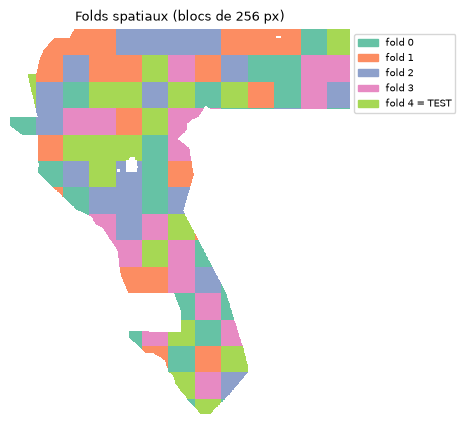

tableau pixels x variables : 5,165,852 lignes


In [7]:
BLOCK, N_FOLDS, TEST_FOLD, BUFFER = 256, 5, 4, 32
nbr, nbc = int(np.ceil(H / BLOCK)), int(np.ceil(W / BLOCK))
blk = (np.arange(H) // BLOCK)[:, None] * nbc + (np.arange(W) // BLOCK)[None, :]
n_faults_blk = np.bincount(blk[LABELED & (Y == 1)], minlength=nbr * nbc)
n_valid_blk = np.bincount(blk[LABELED], minlength=nbr * nbc)

# affectation gloutonne : blocs triés par nombre de failles décroissant, chacun au fold le moins chargé
order = [b for b in np.argsort(-n_faults_blk, kind="stable") if n_valid_blk[b] > 0]
RNG_SPLIT = np.random.default_rng(1)
load = np.zeros(N_FOLDS); fold_of_blk = np.full(nbr * nbc, -1, np.int8)
for b in order:
    cand = np.flatnonzero(load == load.min())
    f = RNG_SPLIT.choice(cand)
    fold_of_blk[b] = f; load[f] += n_faults_blk[b] + 0.02 * n_valid_blk[b] / 1000
FOLD = np.where(VALID, fold_of_blk[blk], -1).astype(np.int8)

tab = pd.DataFrame({
    "fold": range(N_FOLDS),
    "rôle": ["dév. (CV)"] * (TEST_FOLD - 1) + ["dév. (CV) + validation fixe"] + ["TEST final"],
    "blocs": [(fold_of_blk == f).sum() for f in range(N_FOLDS)],
    "pixels": [int((LABELED & (FOLD == f)).sum()) for f in range(N_FOLDS)],
    "pixels faille": [int(((Y == 1) & (FOLD == f)).sum()) for f in range(N_FOLDS)],
})
tab["% faille"] = (100 * tab["pixels faille"] / tab["pixels"]).round(2)
print(tab.to_string(index=False))

cmap_f = ListedColormap(["white"] + list(plt.cm.Set2.colors[:N_FOLDS]))
from matplotlib.patches import Patch
plt.figure(figsize=(5.5, 5))
plt.imshow(np.where(FOLD >= 0, FOLD + 1, 0)[::4, ::4], cmap=cmap_f, interpolation="nearest")
plt.legend(handles=[Patch(color=cmap_f(f + 1), label=f"fold {f}" + (" = TEST" if f == TEST_FOLD else "")) for f in range(N_FOLDS)],
           loc="upper left", bbox_to_anchor=(1, 1), fontsize=7)
plt.title("Folds spatiaux (blocs de 256 px)"); plt.axis("off"); plt.show()

# distance (en pixels) de chaque pixel à chaque fold : sert à créer la zone tampon train/validation
DIST_TO_FOLD = np.stack([np.minimum(ndi.distance_transform_edt(FOLD != f), 255).astype(np.uint8)
                         for f in range(N_FOLDS)])
VIDX = np.flatnonzero(VALID.ravel())          # indices (dans la carte aplatie) des pixels valides = lignes du tableau
N = VIDX.size
ROW_Y = Y.ravel()[VIDX]                       # -1 / 0 / 1
ROW_FOLD = FOLD.ravel()[VIDX]
ROW_DIST = DIST_TO_FOLD.reshape(N_FOLDS, -1)[:, VIDX]
print(f"tableau pixels x variables : {N:,} lignes")

## 4. Feature engineering par filtres de convolution

Un pixel seul (19 mesures) ignore sa **géométrie locale** : or une faille est une structure **linéaire, orientée, multi-échelle**. On construit donc, **pour chacune des 19 cartes**, un *hyper-cube* de cartes filtrées , puis chaque pixel devient une ligne et chaque filtre une colonne **nommée** (interprétable).

| Famille | Filtre (scikit-image / SciPy) | Ce qu'il détecte | Paramètres | Colonnes / bande |
|---|---|---|---|---|
| `raw` | valeur brute | information ponctuelle | – | 1 |
| `mean`, `std` | moyenne / écart-type sur fenêtre | niveau régional, hétérogénéité locale | fenêtres 3×3 et 11×11 | 4 |
| `frangi` | **Frangi** (valeurs propres de la Hessienne) | structures tubulaires/linéaires, quelle que soit leur orientation | σ = 1, 2, 4, 8 | 4 |
| `gabor` | **banc de Gabor** (8 orientations) | textures orientées ; direction privilégiée | σ = 1, 2, 4, 8 | 4 + 4 |
| `wth`, `bth` | **Top-Hat** blanc / noir (morphologie) | petites crêtes claires / sombres | disque de rayon 1, 2, 4, 8 | 8 |
| `sobel` | **Sobel** après lissage gaussien (contours) | intensité des gradients (contours) | σ = 1, 2, 4, 8 | 4 |

**29 colonnes × 19 cartes = 551 variables.** Choix de conception (chacun répond à un verrou) :
* **Normalisation robuste avant filtrage** : $z=\operatorname{arcsinh}\big((x-\text{médiane})/\sigma_{\text{robuste}}\big)$. Les 19 bandes ont des échelles très différentes et des queues très lourdes (distance aux séismes jusqu'à 5·10⁶) ; Frangi et Gabor dépendent de l'amplitude de l'image. Les colonnes `raw` restent en unités d'origine.
* **Bords** : pour `mean`/`std`, la fenêtre est **tronquée** aux pixels réellement valides (moyenne normalisée par le nombre de voisins valides) → les pixels du bord de la carte *et* du bord de la zone d'étude sont conservés. Pour les autres filtres, les `NaN` sont remplis par le **plus proche voisin valide** (évite un bord artificiel) et les bords de la carte sont traités par réflexion.
* **Gabor** : 8 orientations × 4 échelles × 19 cartes = 608 colonnes serait ingérable ; on **résume le banc** par échelle : réponse maximale sur les angles (force), et direction dominante de la structure encodée en $(\cos 2\varphi,\sin 2\varphi)$ (cyclique, pondérée par les réponses) aux échelles locale (σ = 2) et régionale (σ = 8). Le noyau est allongé (σ_y = 2σ) pour être sélectif en orientation.
* **Frangi** : polarité-agnostique, $\max$(crêtes claires, crêtes sombres), une colonne par σ pour garder l'échelle lisible.

In [8]:
from skimage.filters import frangi, sobel, gaussian, gabor_kernel
from skimage.morphology import white_tophat, black_tophat, disk

SCALES = (1, 2, 4, 8)
ANGLES = np.arange(8) * np.pi / 8                      # 8 orientations du banc de Gabor
SUFFIXES = (["raw", "mean3", "mean11", "std3", "std11"]
            + [f"frangi_s{s}" for s in SCALES]
            + [f"gabor_s{s}" for s in SCALES] + ["gabor_cos_s2", "gabor_sin_s2", "gabor_cos_s8", "gabor_sin_s8"]
            + [f"wth_r{s}" for s in SCALES] + [f"bth_r{s}" for s in SCALES]
            + [f"sobel_s{s}" for s in SCALES])
FEATURES = [f"{b}__{s}" for b in BAND_NAMES for s in SUFFIXES]
FAMILY = {"raw": "brute", "mean": "moy./écart-type", "std": "moy./écart-type", "frangi": "Frangi", "gabor": "Gabor",
          "wth": "Top-Hat", "bth": "Top-Hat", "sobel": "Sobel"}
fam_of = lambda feat: FAMILY[feat.split("__")[1].split("_")[0].rstrip("0123456789")]
FEAT_FAMILY = np.array([fam_of(f) for f in FEATURES])
print(len(SUFFIXES), "colonnes par carte ->", len(FEATURES), "variables")


def band_feature_maps(band, mask):
    """Génère (suffixe, carte filtrée) pour une bande ; toutes les cartes ont la taille (H, W)."""
    ok = mask & ~np.isnan(band)
    v = band[ok]
    q1, q3 = np.percentile(v, [25, 75])
    scale = (q3 - q1) / 1.349 or v.std()
    z = np.arcsinh((band - np.median(v)) / scale).astype(np.float32)
    idx = ndi.distance_transform_edt(~ok, return_distances=False, return_indices=True)
    zf = z[tuple(idx)]                                            # NaN -> plus proche voisin valide
    w = ok.astype(np.float64); zw = np.where(ok, z, 0.0).astype(np.float64)

    yield "raw", band
    for size in (3, 11):                                          # fenêtres tronquées aux pixels valides
        n = np.maximum(ndi.uniform_filter(w, size, mode="constant"), 1e-9)
        m1 = ndi.uniform_filter(zw, size, mode="constant") / n
        m2 = ndi.uniform_filter(zw ** 2, size, mode="constant") / n
        yield f"mean{size}", m1.astype(np.float32)
        yield f"std{size}", np.sqrt(np.maximum(m2 - m1 ** 2, 0)).astype(np.float32)
    for s in SCALES:
        yield f"frangi_s{s}", np.maximum(frangi(zf, sigmas=[s], black_ridges=False),
                                         frangi(zf, sigmas=[s], black_ridges=True))
    gab = {}
    for s in SCALES:
        mags = []
        for th in ANGLES:
            k = gabor_kernel(0.35 / s, theta=th, sigma_x=s, sigma_y=2 * s)
            re = fftconvolve(zf, k.real.astype(np.float32), mode="same")
            im = fftconvolve(zf, k.imag.astype(np.float32), mode="same")
            mags.append(np.hypot(re, im))
        mags = np.stack(mags)
        yield f"gabor_s{s}", mags.max(0)
        if s in (2, 8):
            phi = ANGLES + np.pi / 2                              # orientation de la structure (perpendiculaire à l'onde)
            tot = mags.sum(0) + 1e-6
            gab[s] = ((mags * np.cos(2 * phi)[:, None, None]).sum(0) / tot,
                      (mags * np.sin(2 * phi)[:, None, None]).sum(0) / tot)
        del mags
    for s in (2, 8):
        yield f"gabor_cos_s{s}", gab[s][0]
        yield f"gabor_sin_s{s}", gab[s][1]
    for s in SCALES:
        yield f"wth_r{s}", white_tophat(zf, disk(s))
    for s in SCALES:
        yield f"bth_r{s}", black_tophat(zf, disk(s))
    for s in SCALES:
        yield f"sobel_s{s}", sobel(gaussian(zf, s))


def compute_band(i, band, path, vidx, mask):
    mm = np.load(path, mmap_mode="r+")
    for suffix, m in band_feature_maps(band, mask):
        mm[FEATURES.index(f"{BAND_NAMES[i]}__{suffix}")] = m.ravel()[vidx].astype(np.float32)
    mm.flush()
    return i


FEAT_PATH = PROC / "hypercube_T.npy"          # (551, N) : une ligne mémoire par variable, lecture colonne par colonne
if not FEAT_PATH.exists():
    t0 = time.time()
    tmp = PROC / "hypercube_T.tmp.npy"
    np.lib.format.open_memmap(tmp, mode="w+", dtype=np.float32, shape=(len(FEATURES), N)).flush()
    Parallel(n_jobs=6, verbose=5)(delayed(compute_band)(i, X[i], tmp, VIDX, VALID) for i in range(NB))
    tmp.rename(FEAT_PATH)
    print(f"hypercube calculé en {(time.time() - t0) / 60:.1f} min")
FEAT = np.load(FEAT_PATH, mmap_mode="r")
print("hypercube :", FEAT.shape, f"({FEAT.nbytes / 1e9:.1f} Go, float32)")


def get_rows(rows, cols=None):
    """Lit les lignes `rows` (indices triés) du tableau pixels x variables -> matrice (len(rows), len(cols))."""
    cols = range(len(FEATURES)) if cols is None else cols
    out = np.empty((len(rows), len(cols)), np.float32)
    for j, c in enumerate(cols):
        out[:, j] = FEAT[c][rows]
    return out


def feature_map(name):
    """Reconstruit la carte (H, W) d'une variable (pour la visualisation)."""
    m = np.full(H * W, np.nan, np.float32)
    m[VIDX] = FEAT[FEATURES.index(name)]
    return m.reshape(H, W)

29 colonnes par carte -> 551 variables
hypercube : (551, 5165852) (11.4 Go, float32)


**Illustration des filtres** sur une fenêtre de 400 × 400 pixels riche en failles (carte `tmi_vg`, gradient vertical du champ magnétique) : on voit comment chaque filtre transforme le signal brut en une variable plus proche du concept de « faille ».

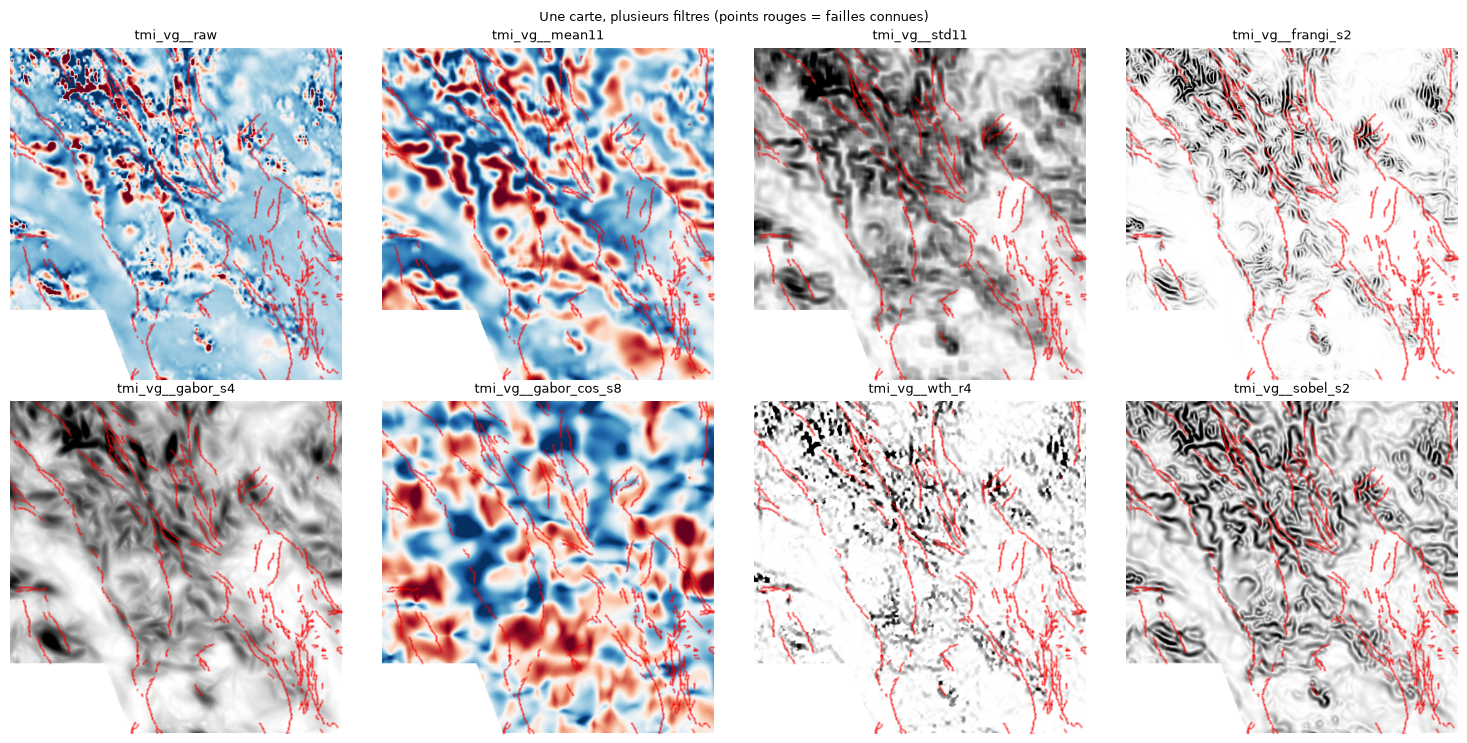

In [9]:
cnt = ndi.uniform_filter((Y == 1).astype(np.float32), 400)
cy, cx = np.unravel_index(np.argmax(np.where(VALID, cnt, 0)), cnt.shape)
ys, xs = slice(max(cy - 200, 0), cy + 200), slice(max(cx - 200, 0), cx + 200)
shown = ["raw", "mean11", "std11", "frangi_s2", "gabor_s4", "gabor_cos_s8", "wth_r4", "sobel_s2"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, suf in zip(axes.ravel(), shown):
    m = feature_map(f"tmi_vg__{suf}")[ys, xs]
    lo, hi = np.nanpercentile(m, [2, 99])
    ax.imshow(m, cmap="gray_r" if suf not in ("mean11", "raw", "gabor_cos_s8") else "RdBu_r", vmin=lo, vmax=hi)
    fy, fx = np.nonzero(Y[ys, xs] == 1)
    ax.scatter(fx, fy, s=0.3, c="red", alpha=0.35)
    ax.set_title(f"tmi_vg__{suf}"); ax.axis("off")
plt.suptitle("Une carte, plusieurs filtres (points rouges = failles connues)")
plt.tight_layout(); plt.show()

## 5. Échantillonnage et protocole de comparaison

**Verrous n°2 et 4 du §13 : volumétrie et déséquilibre.** Le tableau complet fait 5,2 M lignes × 551 colonnes (≈ 11 Go) et seulement 1,2 % de lignes positives. Entraîner et comparer des dizaines de modèles dessus est impossible. **Solution** : on garde **tous les pixels de faille** et seulement **10 % des pixels sans faille** (tirage aléatoire), soit ≈ 570 000 lignes avec ≈ 11 % de positifs. Conséquences à maîtriser :
* les probabilités apprises sont **surestimées** ; on les corrige par le changement de prior : $\text{cote}_{\text{réelle}}=0{,}1\times\text{cote}_{\text{échantillon}}$ ;
* les scores en validation croisée sont mesurés sur cet échantillon (prévalence 11 %) : leurs valeurs absolues sont **optimistes**, mais le classement des méthodes est conservé. L'évaluation finale se fera sur **tous** les pixels du fold de test (prévalence réelle).

**Protocole.** Pour valider sur le fold `f` (parmi 0-3) : apprentissage sur les autres folds de développement **hors zone tampon de 32 px**, validation sur `f` ; les scores sont moyennés sur les 4 folds. Pour accélérer les comparaisons, chaque modèle est entraîné sur 30 % de l'échantillon d'apprentissage (`frac`).

In [10]:
NEG_RATE = 0.10
lab_rows = np.flatnonzero(ROW_Y >= 0)
pos_rows, neg_rows = lab_rows[ROW_Y[lab_rows] == 1], lab_rows[ROW_Y[lab_rows] == 0]
neg_keep = np.sort(np.random.default_rng(SEED).choice(neg_rows, int(NEG_RATE * len(neg_rows)), replace=False))
S = np.sort(np.concatenate([pos_rows, neg_keep]))             # lignes de l'échantillon (indices dans le tableau complet)
S_y, S_fold = ROW_Y[S], ROW_FOLD[S]
XS = get_rows(S)                                              # (n_échantillon, 551) en mémoire
print(f"échantillon : {len(S):,} lignes ({S_y.mean():.1%} de positifs) ; matrice {XS.shape}, {XS.nbytes / 1e9:.2f} Go")


def prior_correct(p, rate=NEG_RATE):
    """Corrige la probabilité d'un modèle entraîné avec `rate` des négatifs (changement de prior)."""
    odds = p / np.clip(1 - p, 1e-9, None) * rate
    return odds / (1 + odds)


DEV_FOLDS = [f for f in range(N_FOLDS) if f != TEST_FOLD]


def split_idx(f, train_folds=None):
    """Indices (dans S) d'apprentissage et de validation pour évaluer sur le fold f (zone tampon incluse)."""
    train_folds = [g for g in DEV_FOLDS if g != f] if train_folds is None else train_folds
    tr = np.flatnonzero(np.isin(S_fold, train_folds) & (ROW_DIST[f][S] > BUFFER))
    va = np.flatnonzero(S_fold == f)
    return tr, va


CV_SPLITS = [split_idx(f) for f in DEV_FOLDS]
print("taille apprentissage / validation par fold :", [(len(a), len(b)) for a, b in CV_SPLITS])

échantillon : 571,235 lignes (10.7% de positifs) ; matrice (571235, 551), 1.26 Go
taille apprentissage / validation par fold : [(312609, 108124), (309889, 117706), (302550, 121183), (317532, 110158)]


In [11]:
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif, SelectFromModel, VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import loguniform, randint, uniform

N_JOBS = 12


def lr_pipe(C=0.05, l1_ratio=0.0, scaler="standard", extra=()):
    solver = "lbfgs" if l1_ratio == 0 else "saga"
    sc = StandardScaler() if scaler == "standard" else QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=100_000, random_state=SEED)
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", sc), *extra,
                     ("clf", LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=300, tol=1e-3))])


def hgb_pipe(extra=(), **kw):
    params = dict(learning_rate=0.1, max_iter=150, max_leaf_nodes=31, min_samples_leaf=50, random_state=SEED)
    params.update(kw)
    return Pipeline([*extra, ("clf", HistGradientBoostingClassifier(**params))])


def n_selected(model, n_in):
    """Nombre de variables qui atteignent l'estimateur final (étape « sel » du pipeline si elle existe)."""
    sel = dict(model.steps).get("sel")
    if sel is None:
        return n_in
    if hasattr(sel, "keep_"):
        return len(sel.keep_)
    if hasattr(sel, "get_support"):
        return int(sel.get_support().sum())
    return getattr(sel, "n_components_", n_in)


def cv_eval(model, cols=None, frac=0.3, seed=SEED, splits=CV_SPLITS, verbose=False):
    """Validation croisée spatiale : AP et ROC-AUC (moyenne sur les folds), temps d'ajustement."""
    rng = np.random.default_rng(seed)
    cols = slice(None) if cols is None else cols
    n_in = XS.shape[1] if isinstance(cols, slice) else len(cols)
    res, kept = [], []
    for tr, va in splits:
        tr = np.sort(rng.choice(tr, int(frac * len(tr)), replace=False)) if frac < 1 else tr
        m = clone(model)
        t0 = time.time()
        m.fit(XS[tr][:, cols], S_y[tr])
        fit_t = time.time() - t0
        p = m.predict_proba(XS[va][:, cols])[:, 1]
        res.append((average_precision_score(S_y[va], p), roc_auc_score(S_y[va], p), fit_t))
        kept.append(n_selected(m, n_in))
    r = np.array(res)
    return {"PR-AUC": float(r[:, 0].mean()), "±": float(r[:, 0].std()), "ROC-AUC": float(r[:, 1].mean()),
            "temps/fit (s)": float(r[:, 2].mean()), "vars retenues": float(np.mean(kept))}

## 6. Modèles de référence et apport du feature engineering

On commence par les modeles de ref (Naive Bayes, modèle linéaire, arbre de décision, boosting) sur les **19 variables brutes seules**, puis on ajoute les filtres. Deux questions : *le feature engineering aide-t-il ?* et *quelle famille de filtres apporte quoi ?*

In [12]:
RAW = [i for i, f in enumerate(FEATURES) if f.endswith("__raw")]
MEANSTD = [i for i, f in enumerate(FEATURES) if FEAT_FAMILY[i] == "moy./écart-type"]
ALL = list(range(len(FEATURES)))

rows = []
def add(name, model, cols, frac=0.3):
    r = {"modèle": name, "nb variables": len(cols), **cv_eval(model, cols, frac=frac)}
    r.pop("vars retenues")
    rows.append(r)
    print(f"{name:30s} {len(cols):4d} variables  PR-AUC {r['PR-AUC']:.3f} ± {r['±']:.3f}  ROC-AUC {r['ROC-AUC']:.3f}  ({r['temps/fit (s)']:.1f} s/fit)")

prev = S_y.mean()
print(f"prior (prédire la prévalence) : PR-AUC = {prev:.3f}")
add("Naive Bayes gaussien", Pipeline([("imp", SimpleImputer(strategy="median")), ("clf", GaussianNB())]), RAW)
add("Arbre de décision (prof. 6)", Pipeline([("imp", SimpleImputer(strategy="median")), ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=SEED))]), RAW)
add("Régression logistique", lr_pipe(), RAW)
add("HistGradientBoosting", hgb_pipe(), RAW)
add("Régression logistique", lr_pipe(), RAW + MEANSTD)
add("HistGradientBoosting", hgb_pipe(), RAW + MEANSTD)
add("Régression logistique", lr_pipe(), ALL)
add("HistGradientBoosting", hgb_pipe(), ALL)
baselines = pd.DataFrame(rows)
baselines.index = ["19 brutes"] * 4 + ["+ moy./écart-type (95)"] * 2 + ["+ tous les filtres (551)"] * 2
baselines.round(3)

prior (prédire la prévalence) : PR-AUC = 0.107


Naive Bayes gaussien             19 variables  PR-AUC 0.140 ± 0.017  ROC-AUC 0.590  (0.1 s/fit)


Arbre de décision (prof. 6)      19 variables  PR-AUC 0.163 ± 0.017  ROC-AUC 0.628  (0.8 s/fit)


Régression logistique            19 variables  PR-AUC 0.139 ± 0.020  ROC-AUC 0.603  (0.2 s/fit)


HistGradientBoosting             19 variables  PR-AUC 0.185 ± 0.024  ROC-AUC 0.662  (0.6 s/fit)


Régression logistique            95 variables  PR-AUC 0.227 ± 0.020  ROC-AUC 0.692  (0.7 s/fit)


HistGradientBoosting             95 variables  PR-AUC 0.242 ± 0.031  ROC-AUC 0.703  (1.2 s/fit)


Régression logistique           551 variables  PR-AUC 0.240 ± 0.017  ROC-AUC 0.689  (4.1 s/fit)


HistGradientBoosting            551 variables  PR-AUC 0.288 ± 0.014  ROC-AUC 0.718  (6.3 s/fit)


,modèle,nb variables,PR-AUC,±,ROC-AUC,temps/fit (s)
19 brutes,Naive Bayes gaussien,19,0.140,0.017,0.590,0.149
19 brutes,Arbre de décision (prof. 6),19,0.163,0.017,0.628,0.788
19 brutes,Régression logistique,19,0.139,0.020,0.603,0.157
19 brutes,HistGradientBoosting,19,0.185,0.024,0.662,0.550
+ moy./écart-type (95),Régression logistique,95,0.227,0.020,0.692,0.689
+ moy./écart-type (95),HistGradientBoosting,95,0.242,0.031,0.703,1.175
+ tous les filtres (551),Régression logistique,551,0.240,0.017,0.689,4.063
+ tous les filtres (551),HistGradientBoosting,551,0.288,0.014,0.718,6.308


## 7. Quelle famille de filtres apporte quoi ? (ablation)

Avec 29 colonnes par carte, on veut savoir **quels filtres sont utiles** (interprétabilité) et lesquels sont redondants. Une sélection pas à pas variable par variable coûterait des milliers d'ajustements sur 551 colonnes : on la réalise donc **au niveau des familles de filtres** (6 familles) avec HistGradientBoosting :
* **brutes + une famille** : gain apporté par une famille seule (*forward*) ;
* **tout sauf une famille** : perte quand on la retire (*backward*) ;
* **échelles** locales (fenêtre 3, σ ou rayon ≤ 2) vs régionales (fenêtre 11, σ ou rayon ≥ 4).

In [13]:
import re
FAMS = ["moy./écart-type", "Frangi", "Gabor", "Top-Hat", "Sobel"]
fam_idx = lambda fam: [i for i in ALL if FEAT_FAMILY[i] == fam]
suffix = [f.split("__")[1] for f in FEATURES]
LOCAL = [i for i in ALL if re.fullmatch(r"raw|mean3|std3|.*_[sr][12]", suffix[i])]
REGIONAL = [i for i in ALL if re.fullmatch(r"raw|mean11|std11|.*_[sr][48]", suffix[i])]


def ablation():
    rows = []
    for fam in FAMS:
        a = cv_eval(hgb_pipe(), sorted(set(RAW) | set(fam_idx(fam))))
        b = cv_eval(hgb_pipe(), [i for i in ALL if FEAT_FAMILY[i] != fam])
        rows.append({"famille": fam, "nb variables": len(fam_idx(fam)), "brutes + famille": a["PR-AUC"], "tout sauf famille": b["PR-AUC"]})
        print(rows[-1])
    for name, cols in [("échelles locales", LOCAL), ("échelles régionales", REGIONAL)]:
        a = cv_eval(hgb_pipe(), cols)
        rows.append({"famille": name, "nb variables": len(cols) - len(RAW), "brutes + famille": a["PR-AUC"], "tout sauf famille": np.nan})
        print(rows[-1])
    return pd.DataFrame(rows).set_index("famille")


abl = cached("ablation_v1", ablation)
AP_RAW = baselines.loc["19 brutes"].query("modèle == 'HistGradientBoosting'")["PR-AUC"].iloc[0]
AP_ALL = baselines.loc["+ tous les filtres (551)"].query("modèle == 'HistGradientBoosting'")["PR-AUC"].iloc[0]
abl["gain si ajoutée aux brutes"] = abl["brutes + famille"] - AP_RAW
abl["perte si retirée"] = AP_ALL - abl["tout sauf famille"]
print(f"référence HGB : 19 brutes = {AP_RAW:.3f} ; 551 variables = {AP_ALL:.3f}")
abl.round(3)

référence HGB : 19 brutes = 0.185 ; 551 variables = 0.288


,nb variables,brutes + famille,tout sauf famille,gain si ajoutée aux brutes,perte si retirée
famille,,,,,
moy./écart-type,76,0.242,0.286,0.057,0.002
Frangi,76,0.201,0.284,0.017,0.004
Gabor,152,0.241,0.286,0.056,0.003
Top-Hat,152,0.250,0.280,0.065,0.008
Sobel,76,0.261,0.282,0.076,0.006
échelles locales,266,0.271,NaN,0.086,NaN
échelles régionales,266,0.280,NaN,0.095,NaN


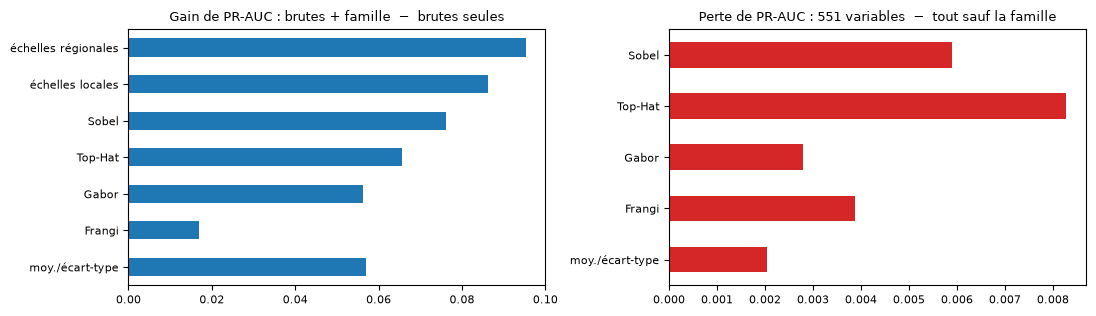

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
abl["gain si ajoutée aux brutes"].plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_title("Gain de PR-AUC : brutes + famille  −  brutes seules"); ax[0].set_ylabel("")
abl["perte si retirée"].dropna().plot.barh(ax=ax[1], color="tab:red"); ax[1].set_title("Perte de PR-AUC : 551 variables  −  tout sauf la famille"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Lecture.** Une seule famille ajoutée aux 19 cartes brutes fait déjà passer la PR-AUC de 0,185 à 0,24-0,26 (Sobel +0,076, Top-Hat +0,065, moyennes/écarts-types +0,057, Gabor +0,056), **sauf Frangi (+0,016)** : le filtre « adapté aux failles » en théorie est le moins utile en pratique, probablement parce que les failles étiquetées sont imprécises et que Frangi, très sélectif, répond à des crêtes fines qui ne coïncident pas avec les traits du masque. Les **échelles régionales** (fenêtre 11, σ ≥ 4) apportent plus que les échelles locales (+0,095 contre +0,086) : une faille se reconnaît à son contexte.
À l'inverse, **retirer une seule famille ne coûte presque rien** (−0,002 à −0,008) : les familles sont fortement redondantes entre elles, aucune n'est indispensable. Cela justifie d'étudier la sélection de variables.

## 8. Sélection de variables vs sans sélection

Il y a 3 grandes stratégies : **filtres** (corrélation, test statistique), **méthodes intégrées** (pénalisation L1/L2, importance des arbres) et **méthodes enveloppantes** (forward / backward, vues plus haut au niveau des familles), auxquelles s'ajoute la **réduction de dimension**.

**Point méthodologique important.** La sélection est une étape du `Pipeline` : elle est donc **réajustée sur le seul jeu d'apprentissage de chaque fold**. Choisir les variables sur l'ensemble des données avant la validation croisée serait une fuite d'information (les scores seraient optimistes).

On compare, à modèle identique (régression logistique et HistGradientBoosting) :
1. **aucune sélection** (551 variables) ;
2. **filtre de corrélation** : on supprime une variable si $|\rho|>0{,}95$ avec une variable déjà retenue (on garde d'abord les brutes, puis les moyennes, etc.) ;
3. **F-test univarié** (`SelectKBest(f_classif)`), $k=50$ et $k=100$ ;
4. **pénalisation L1** : variables à coefficient non nul d'une régression logistique L1 (`SelectFromModel`) ;
5. **importance d'arbres** : les 50 meilleures variables d'une forêt `ExtraTrees` ;
6. **PCA** : 50 composantes principales.

In [15]:
class CorrFilter(BaseEstimator, TransformerMixin):
    """Filtre de corrélation : on parcourt les variables dans l'ordre et on supprime celles trop corrélées (|ρ| > thr) à une variable déjà gardée."""
    def __init__(self, thr=0.95, n_max=40_000, seed=SEED):
        self.thr, self.n_max, self.seed = thr, n_max, seed

    def fit(self, X, y=None):
        idx = np.random.default_rng(self.seed).choice(len(X), min(self.n_max, len(X)), replace=False)
        C = np.nan_to_num(np.abs(np.corrcoef(X[idx], rowvar=False)))
        keep = []
        for j in range(C.shape[0]):
            if not keep or C[j, keep].max() <= self.thr:
                keep.append(j)
        self.keep_ = np.array(keep)
        return self

    def transform(self, X):
        return X[:, self.keep_]


def prep():
    return [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]


SELECTORS = {
    "aucune (551)": None,
    "corrélation |ρ| ≤ 0,95": CorrFilter(0.95),
    "F-test, k = 50": SelectKBest(f_classif, k=50),
    "F-test, k = 100": SelectKBest(f_classif, k=100),
    "L1 (rég. logistique)": SelectFromModel(LogisticRegression(l1_ratio=1.0, solver="saga", C=0.005, max_iter=200, tol=1e-3), threshold=1e-8),
    "ExtraTrees, top 50": SelectFromModel(ExtraTreesClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED),
                                          max_features=50, threshold=-np.inf),
    "PCA, 50 composantes": PCA(n_components=50, random_state=SEED),
}


def make(kind, sel, **kw):
    steps = [("sel", clone(sel))] if sel is not None else []
    if kind == "LR":
        return lr_pipe(extra=steps, **kw)
    return hgb_pipe(extra=prep() + steps, **kw)


def sel_table():
    rows = []
    for name, sel in SELECTORS.items():
        for kind, label in [("LR", "Régression logistique"), ("HGB", "HistGradientBoosting")]:
            r = {"sélection": name, "modèle": label, **cv_eval(make(kind, sel))}
            rows.append(r)
            print(f"{name:26s} {label:22s} vars {r['vars retenues']:5.0f}  PR-AUC {r['PR-AUC']:.3f} ± {r['±']:.3f}  ROC-AUC {r['ROC-AUC']:.3f}  fit {r['temps/fit (s)']:.1f}s")
    return pd.DataFrame(rows)


sel_df = cached("selection_v1", sel_table)

In [16]:
tab = sel_df.pivot(index="sélection", columns="modèle", values=["PR-AUC", "vars retenues", "temps/fit (s)"]).loc[list(SELECTORS)]
tab.round(3)

PR-AUC                        \
modèle                 HistGradientBoosting Régression logistique   
sélection                                                           
aucune (551)                          0.287                 0.240   
corrélation |ρ| ≤ 0,95                0.290                 0.234   
F-test, k = 50                        0.262                 0.236   
F-test, k = 100                       0.266                 0.236   
L1 (rég. logistique)                  0.278                 0.240   
ExtraTrees, top 50                    0.270                 0.250   
PCA, 50 composantes                   0.230                 0.215   

                              vars retenues                        \
modèle                 HistGradientBoosting Régression logistique   
sélection                                                           
aucune (551)                         551.00                551.00   
corrélation |ρ| ≤ 0,95               444.75                444.75   
F-test, k = 50                        50.00                 50.00   
F-test, k = 100                      100.00                100.00   
L1 (rég. logistique)                 113.50                113.00   
ExtraTrees, top 50                    50.00                 50.00   
PCA, 50 composantes                   50.00                 50.00   

                              temps/fit (s)                        
modèle                 HistGradientBoosting Régression logistique  
sélection                                                          
aucune (551)                          8.419                 3.544  
corrélation |ρ| ≤ 0,95                7.995                 3.629  
F-test, k = 50                        3.857                 3.474  
F-test, k = 100                       4.201                 3.463  
L1 (rég. logistique)                 38.401                36.632  
ExtraTrees, top 50                    7.043                 6.503  
PCA, 50 composantes                   4.194                 3.511

**Lecture** (PR-AUC en validation croisée spatiale ; le ± entre folds est large car les blocs géographiques sont hétérogènes, mais toutes les méthodes sont comparées **sur les mêmes folds**).
* **HistGradientBoosting** : aucune sélection (0,287) ≈ filtre de corrélation (0,290 avec 445 variables) > L1 (0,278 avec 114) > ExtraTrees top 50 (0,270) > F-test (0,262-0,266) > **PCA (0,230)**. Aucune sélection ne bat vraiment le modèle complet : le boosting sait déjà ignorer les variables inutiles. La sélection sert à **gagner en lisibilité et en temps** (50 variables : ajustement 2 fois plus rapide pour −0,017 de PR-AUC).
* **Régression logistique** : elle plafonne vers 0,24 quelle que soit la sélection (relation variables → failles trop non linéaire) ; seule la sélection par **importance d'arbres** l'améliore (0,250 avec 50 variables) : le modèle linéaire profite des variables repérées par un modèle non linéaire.
* Le **F-test** juge chaque variable isolément et garde des variables redondantes (un même signal à plusieurs échelles) ; la **PCA**, non supervisée, retient la variance et non l'information sur les failles : c'est la plus mauvaise.
* Les méthodes **intégrées** (L1, arbres) sont les meilleurs compromis nombre de variables / score.

**Courbe de sélection.** On fait varier le nombre $k$ de variables conservées par le F-test (toujours dans le `Pipeline`, donc recalculé dans chaque fold) pour voir à partir de quand le score sature.

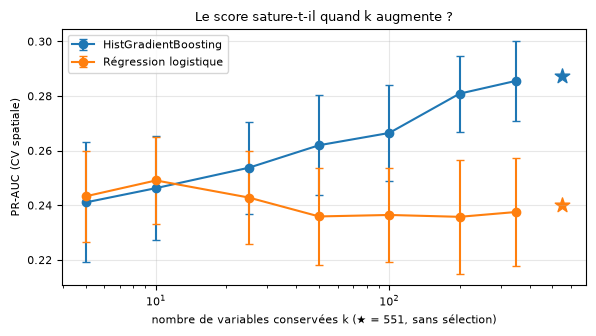

In [17]:
KS = [5, 10, 25, 50, 100, 200, 350]


def kcurve():
    rows = []
    for k in KS:
        for kind, label in [("LR", "Régression logistique"), ("HGB", "HistGradientBoosting")]:
            rows.append({"k": k, "modèle": label, **cv_eval(make(kind, SelectKBest(f_classif, k=k)))})
            print(k, label, round(rows[-1]["PR-AUC"], 3))
    return pd.DataFrame(rows)


kc = cached("kcurve_v1", kcurve)
fig, ax = plt.subplots(figsize=(6, 3.4))
for label, g in kc.groupby("modèle"):
    ax.errorbar(g["k"], g["PR-AUC"], g["±"], marker="o", capsize=3, label=label)
    full = sel_df.query("sélection == 'aucune (551)' and modèle == @label")["PR-AUC"].iloc[0]
    ax.scatter([551], [full], marker="*", s=120, color=ax.lines[-1].get_color())
ax.set_xscale("log"); ax.set_xlabel("nombre de variables conservées k (★ = 551, sans sélection)"); ax.set_ylabel("PR-AUC (CV spatiale)")
ax.set_title("Le score sature-t-il quand k augmente ?"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Lecture.** Le boosting continue de progresser jusqu'à plusieurs centaines de variables (0,24 avec 5 variables, 0,29 avec 350) : l'information est **diffuse**, répartie sur beaucoup de filtres. La régression logistique, elle, est déjà saturée à 10 variables : elle ne sait pas exploiter davantage de variables.

**Quelles variables sont retenues ?** On ajuste les trois sélecteurs « classement » sur l'ensemble des folds de développement (jamais sur le fold de test) et on regarde la composition de leurs 50 meilleures variables : par famille de filtres et par carte d'origine.

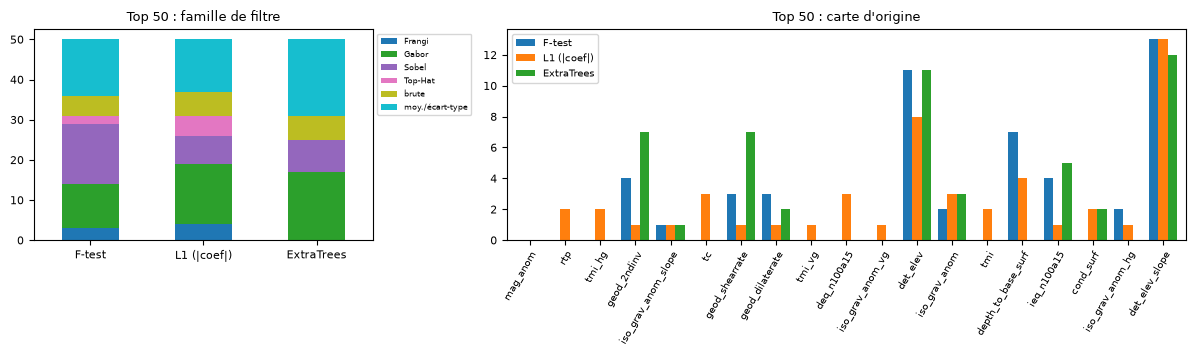

recouvrement (Jaccard) des top 50 : {'F-test / L1 (|coef|)': 0.25, 'F-test / ExtraTrees': 0.41, 'L1 (|coef|) / ExtraTrees': 0.23}


,variable (ExtraTrees),rang F-test
0,det_elev_slope__sobel_s4,1
1,det_elev_slope__sobel_s8,3
2,det_elev_slope__sobel_s2,2
3,det_elev_slope__sobel_s1,4
4,det_elev_slope__std11,5
5,det_elev__sobel_s8,7
6,det_elev_slope__gabor_s8,10
7,det_elev_slope__mean11,358
8,det_elev__sobel_s4,6
9,det_elev_slope__gabor_s4,13


In [18]:
def rankings():
    dev = np.flatnonzero(S_fold != TEST_FOLD)
    dev = np.sort(np.random.default_rng(SEED).choice(dev, 120_000, replace=False))
    Z = Pipeline(prep()).fit_transform(XS[dev]); yd = S_y[dev]
    f_stat = np.nan_to_num(f_classif(Z, yd)[0])
    l1 = LogisticRegression(l1_ratio=1.0, solver="saga", C=0.005, max_iter=300, tol=1e-3).fit(Z, yd)
    et = ExtraTreesClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED).fit(Z, yd)
    return {"F-test": f_stat, "L1 (|coef|)": np.abs(l1.coef_[0]), "ExtraTrees": et.feature_importances_}


RANK = cached("rankings_v1", rankings)
TOP = {k: np.argsort(-v)[:50] for k, v in RANK.items()}
band_of = np.array([f.split("__")[0] for f in FEATURES])

comp_fam = pd.DataFrame({k: pd.Series(FEAT_FAMILY[v]).value_counts() for k, v in TOP.items()}).fillna(0).astype(int)
comp_band = pd.DataFrame({k: pd.Series(band_of[v]).value_counts() for k, v in TOP.items()}).reindex(BAND_NAMES).fillna(0).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2]})
comp_fam.T.plot.bar(stacked=True, ax=ax[0], colormap="tab10", rot=0); ax[0].set_title("Top 50 : famille de filtre"); ax[0].legend(fontsize=6, loc="upper left", bbox_to_anchor=(1, 1))
comp_band.plot.bar(ax=ax[1], rot=60, width=.8); ax[1].set_title("Top 50 : carte d'origine"); ax[1].legend(fontsize=7)
ax[1].tick_params(axis="x", labelsize=7); plt.setp(ax[1].get_xticklabels(), ha="right", rotation_mode="anchor")
plt.tight_layout(); plt.show()
jac = lambda a, b: len(set(a) & set(b)) / len(set(a) | set(b))
print("recouvrement (Jaccard) des top 50 :", {f"{a} / {b}": round(jac(TOP[a], TOP[b]), 2) for a, b in itertools.combinations(TOP, 2)})
pd.DataFrame({"variable (ExtraTrees)": [FEATURES[i] for i in TOP["ExtraTrees"][:12]],
              "rang F-test": [int((RANK["F-test"] > RANK["F-test"][i]).sum()) + 1 for i in TOP["ExtraTrees"][:12]]})

**Lecture.** Les trois méthodes ne sont pas d'accord (recouvrement des top 50 : 0,23 à 0,41) mais convergent sur l'essentiel :
* **les cartes de topographie** (`det_elev`, `det_elev_slope`) fournissent à elles seules ≈ 23 des 50 variables, et les 10 premières variables d'ExtraTrees sont presque toutes des **contours de la pente** (Sobel à plusieurs échelles, écart-type 11×11) : le modèle apprend surtout à repérer des **escarpements topographiques** ;
* viennent ensuite les cartes de déformation (`geod_shearrate`, `geod_2ndinv`) et la profondeur du socle ;
* côté filtres, **Sobel, Gabor et moyennes/écarts-types** dominent ; **Frangi** et **Top-Hat** n'apparaissent presque jamais dans le top 50 d'ExtraTrees. Pour Frangi c'est cohérent avec l'ablation ; pour Top-Hat, c'est plus nuancé : seul il aide (+0,065) et c'est la famille dont le retrait coûte le plus (−0,008), les classements de variables sous-estiment donc ses apports complémentaires.
*Réserve* : la topographie est aussi ce qui sert souvent à **tracer** les failles à la main ; le modèle apprend donc en partie la manière dont les géologues ont cartographié (voir analyse critique).

**PCA.** La PCA est une réduction de dimension *non supervisée* : elle ne sait pas où sont les failles. On regarde la variance expliquée et la projection sur les deux premières composantes.

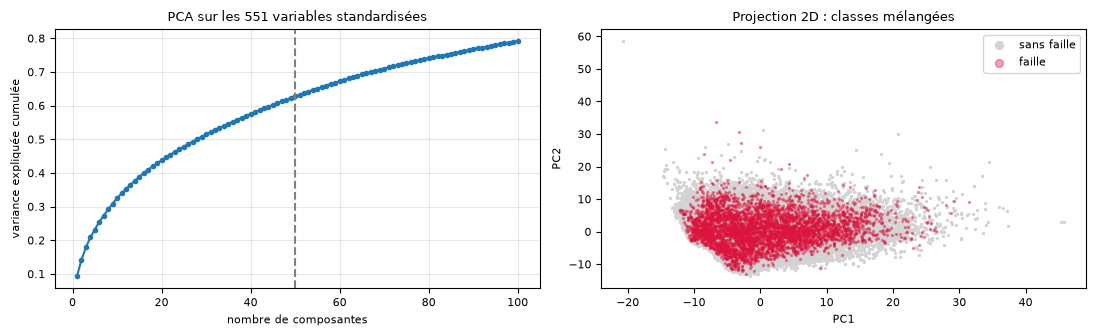

PC1 + PC2 expliquent 14% ; 50 composantes : 63%


In [19]:
idx = np.random.default_rng(SEED).choice(np.flatnonzero(S_fold != TEST_FOLD), 40_000, replace=False)
Zp = Pipeline(prep()).fit_transform(XS[idx]); pca = PCA(n_components=100, random_state=SEED).fit(Zp)
P = pca.transform(Zp)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.arange(1, 101), np.cumsum(pca.explained_variance_ratio_), "o-", ms=3); ax[0].axvline(50, color="gray", ls="--")
ax[0].set_xlabel("nombre de composantes"); ax[0].set_ylabel("variance expliquée cumulée"); ax[0].set_title("PCA sur les 551 variables standardisées"); ax[0].grid(alpha=.3)
neg, pos = S_y[idx] == 0, S_y[idx] == 1
ax[1].scatter(P[neg, 0], P[neg, 1], s=2, c="lightgray", label="sans faille"); ax[1].scatter(P[pos, 0], P[pos, 1], s=2, c="crimson", alpha=.4, label="faille")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Projection 2D : classes mélangées"); ax[1].legend(markerscale=4)
plt.tight_layout(); plt.show()
print(f"PC1 + PC2 expliquent {pca.explained_variance_ratio_[:2].sum():.0%} ; 50 composantes : {pca.explained_variance_ratio_[:50].sum():.0%}")

**Lecture.** La variance est très étalée (PC1 + PC2 = 14 %, 50 composantes = 63 %) et, dans le plan des deux premières composantes, **failles et non-failles sont entièrement mélangées** : aucune direction de grande variance ne sépare les classes. Garder 50 composantes perd donc de l'information utile (PR-AUC 0,23 contre 0,29), ce qui explique la mauvaise note de la PCA plus haut.

**Clustering.** Si les failles formaient des « familles » naturelles de pixels, un **K-means** sur les composantes principales les isolerait dans un ou plusieurs groupes. On le vérifie : taux de failles dans chacun des 8 groupes (échantillon à 10,7 % de failles).

In [20]:
from sklearn.cluster import MiniBatchKMeans
km = MiniBatchKMeans(n_clusters=8, n_init=5, random_state=SEED).fit(P[:, :20])
yk = S_y[idx]
clu = pd.DataFrame({"effectif": np.bincount(km.labels_), "taux de failles": [yk[km.labels_ == c].mean() for c in range(8)]}).round(3)
print(clu.T.to_string())

                        0         1         2         3         4         5         6         7
effectif         8524.000  6684.000  7280.000  3789.000  6049.000  1942.000  1733.000  3999.000
taux de failles     0.092     0.109     0.095     0.112     0.093     0.122     0.148     0.137


**Lecture.** Le taux de failles varie peu d'un groupe à l'autre (de 9 % à 15 % autour des 10,7 % globaux) : le clustering regroupe les pixels selon la **géologie dominante** (relief, gravimétrie), pas selon la présence de failles. La cible étant disponible, l'apprentissage **supervisé** est le bon outil ; le clustering est écarté (il pourrait au mieux servir de variable supplémentaire, sans intérêt ici).

## 9. Quelle famille de modèles ? 

Avant d'optimiser, on compare plusieurs **familles** de modèles sur les 551 variables, avec leurs réglages par défaut (ou raisonnables) : Naive Bayes, arbre, régression logistique, **forêts aléatoires / ExtraTrees**, **boosting** (HistGradientBoosting) et un petit **réseau de neurones** . L'énoncé impose de retenir un **modèle linéaire** et un **HistGradientBoosting** ; cette comparaison montre qu'ils sont aussi les plus pertinents.

In [21]:
from sklearn.neural_network import MLPClassifier
from joblib import Memory

CV_SM = []                                       # mêmes folds, mais 30 % de l'apprentissage : sert à la recherche d'hyper-paramètres
_r = np.random.default_rng(SEED)
for tr, va in CV_SPLITS:
    CV_SM.append((np.sort(_r.choice(tr, int(0.3 * len(tr)), replace=False)), va))
imp = lambda: ("imp", SimpleImputer(strategy="median"))

ZOO = {
    "Naive Bayes gaussien": Pipeline([imp(), ("clf", GaussianNB())]),
    "Arbre de décision": Pipeline([imp(), ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED))]),
    "Régression logistique": lr_pipe(),
    "Random Forest": Pipeline([imp(), ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED))]),
    "ExtraTrees": Pipeline([imp(), ("clf", ExtraTreesClassifier(n_estimators=150, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED))]),
    "MLP (1 couche de 64)": Pipeline(prep() + [("clf", MLPClassifier((64,), alpha=1e-2, early_stopping=True, n_iter_no_change=5, max_iter=60, random_state=SEED))]),
    "HistGradientBoosting": hgb_pipe(),
}


def zoo():
    rows = []
    for name, m in ZOO.items():
        r = {"modèle": name, **cv_eval(m, frac=1.0, splits=CV_SM)}
        r.pop("vars retenues"); rows.append(r)
        print(f"{name:24s} PR-AUC {r['PR-AUC']:.3f} ± {r['±']:.3f}  ROC-AUC {r['ROC-AUC']:.3f}  fit {r['temps/fit (s)']:.1f}s")
    return pd.DataFrame(rows).set_index("modèle")


zoo_df = cached("zoo_v1", zoo)
zoo_df.round(3)

,PR-AUC,±,ROC-AUC,temps/fit (s)
modèle,,,,
Naive Bayes gaussien,0.136,0.011,0.591,3.153
Arbre de décision,0.224,0.015,0.671,25.643
Régression logistique,0.240,0.017,0.689,3.769
Random Forest,0.285,0.014,0.715,18.762
ExtraTrees,0.281,0.015,0.714,9.225
MLP (1 couche de 64),0.210,0.017,0.654,9.624
HistGradientBoosting,0.288,0.014,0.718,5.720


**Lecture.** Les modèles d'arbres en ensemble (RandomForest 0,285, ExtraTrees 0,281, boosting 0,288) dominent largement Naive Bayes (0,14 : il suppose les variables indépendantes alors qu'elles sont très corrélées), l'arbre seul (0,22 : variance élevée) et le modèle linéaire (0,24). Le **boosting** égale la forêt pour un temps d'ajustement 3 fois plus court (6 s contre 19 s). Le **MLP** (0,21) fait même moins bien que la régression logistique : avec ~90 000 pixels très corrélés et des variables déjà « ingénierées », il sur-apprend (un CNN travaillant directement sur les images remplacerait le feature engineering mais sort du cadre de ce projet : cf. perspectives). On retient donc, comme demandé, **un modèle linéaire** (régression logistique, interprétable) et **HistGradientBoosting** (performant).

## 10. Optimisation des hyper-paramètres

**Principe** . Les hyper-paramètres ne sont **jamais** réglés sur le fold de test : on utilise la validation croisée spatiale à 4 folds (folds 0-3). On utilise `RandomizedSearchCV` plutôt que `GridSearchCV` : pour un budget fixe, une recherche aléatoire explore mieux les hyper-paramètres qui comptent vraiment (Bergstra & Bengio), et on peut tirer les valeurs continues selon une loi log-uniforme. La métrique optimisée est `average_precision` (PR-AUC), adaptée aux classes déséquilibrées.

**Chaînes de traitement** (même `Pipeline`, même recherche) :
* **A : sans sélection** : imputation → standardisation → modèle (551 variables) ;
* **B : avec sélection** : imputation → standardisation → `SelectFromModel(ExtraTrees)` → modèle. Le nombre de variables conservées $k \in \{50, 100, 200\}$ est **un hyper-paramètre comme les autres**.

**Espaces de recherche.** *Régression logistique* : force de régularisation $C$ (log-uniforme de $3\cdot10^{-4}$ à $0{,}1$), **type de pénalité** (L2, elastic-net ou L1 via `l1_ratio`) et normalisation (`StandardScaler` ou `QuantileTransformer`). *HistGradientBoosting* : taux d'apprentissage, nombre d'itérations, nombre de feuilles, taille minimale d'une feuille, régularisation L2 et fraction de variables tirées par arbre.

**Astuce de calcul** : le paramètre `memory` du `Pipeline` met en cache les étapes de prétraitement/sélection déjà ajustées sur un fold donné : la forêt de sélection n'est ajustée qu'une fois par fold et par $k$, pas à chaque candidat.

Chaque candidat est évalué sur 30 % de l'apprentissage (≈ 93 000 lignes) pour tenir le budget ; le meilleur est ensuite réévalué avec tout l'apprentissage.

In [4]:
MEM = Memory(PROC / "pipe_cache", verbose=0)
SEL_ET = lambda k=50: SelectFromModel(ExtraTreesClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED),
                                      max_features=k, threshold=-np.inf)


def chain(model, selection):
    """Pipeline complet : chaîne A (sans sélection) ou B (sélection ExtraTrees), modèle 'LR' ou 'HGB'."""
    steps = prep() + ([("sel", SEL_ET())] if selection else [])
    if model == "LR":
        clf = LogisticRegression(C=0.05, l1_ratio=0.0, solver="saga", max_iter=150, tol=1e-3)
    else:
        clf = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=150, max_leaf_nodes=31, min_samples_leaf=50, random_state=SEED)
    return Pipeline(steps + [("clf", clf)], memory=MEM)


QT = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=100_000, random_state=SEED)
SPACE = {
    "LR": {"clf__C": loguniform(3e-4, 0.1), "clf__l1_ratio": [0.0, 0.5, 1.0], "sc": [StandardScaler(), QT]},   # l1_ratio : 0 = L2, 1 = L1, 0.5 = elastic-net
    "HGB": {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_iter": randint(100, 401), "clf__max_leaf_nodes": randint(8, 64),
            "clf__min_samples_leaf": randint(20, 500), "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_features": uniform(0.1, 0.5)},
}
N_ITER = {"LR": 16, "HGB": 14}
VER = {"LR": "v2", "HGB": "v1"}


def search(model, selection):
    space = dict(SPACE[model])
    if selection:
        space["sel__max_features"] = [50, 100, 200]
    rs = RandomizedSearchCV(chain(model, selection), space, n_iter=N_ITER[model], scoring="average_precision", cv=CV_SM,
                            random_state=SEED, n_jobs=4 if model == "LR" else 1, refit=False, return_train_score=False)
    t0 = time.time(); rs.fit(XS, S_y)
    print(f"{model} {'B' if selection else 'A'} : {time.time() - t0:.0f} s, meilleur PR-AUC {rs.best_score_:.3f}")
    return pd.DataFrame(rs.cv_results_), rs.best_params_

NameError: name 'Memory' is not defined

In [23]:
SEARCH = {}
for model, selection in [("LR", False), ("LR", True), ("HGB", False), ("HGB", True)]:
    SEARCH[(model, selection)] = cached(f"search_{model}_{'B' if selection else 'A'}_{VER[model]}", lambda m=model, s=selection: search(m, s))

**Sensibilité aux hyper-paramètres.** Chaque point est un candidat tiré au hasard (chaîne A, HistGradientBoosting) : on voit quels hyper-paramètres influencent réellement le score.

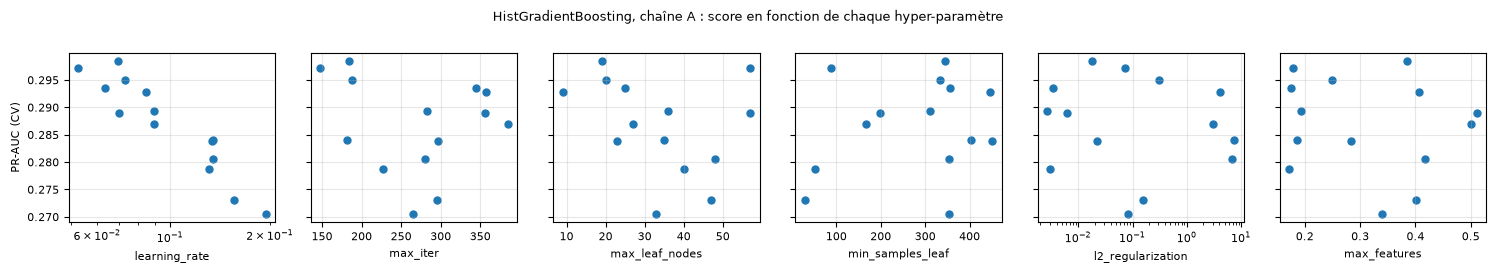

In [24]:
res, _ = SEARCH[("HGB", False)]
hp = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_features"]
fig, ax = plt.subplots(1, 6, figsize=(15, 2.6), sharey=True)
for a, h in zip(ax, hp):
    a.scatter(res[f"param_clf__{h}"].astype(float), res["mean_test_score"], c="tab:blue", s=25)
    a.set_xlabel(h)
    if h in ("learning_rate", "l2_regularization"):
        a.set_xscale("log")
    a.grid(alpha=.3)
ax[0].set_ylabel("PR-AUC (CV)"); fig.suptitle("HistGradientBoosting, chaîne A : score en fonction de chaque hyper-paramètre", y=1.02, fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.** Le **taux d'apprentissage** est de loin l'hyper-paramètre le plus influent : les meilleurs candidats (PR-AUC ≈ 0,295-0,298) ont $\eta<0{,}1$ avec 150-350 itérations, alors que $\eta>0{,}13$ coûte environ 0,02 (sur-apprentissage rapide : 93 000 pixels très corrélés entre voisins). Les autres hyper-paramètres (taille des feuilles, `min_samples_leaf`, régularisation L2, fraction de variables par arbre) donnent un **plateau** sans tendance nette : le réglage est peu critique, ce qui rassure sur la robustesse du modèle.

**Chemin de régularisation de la régression logistique**. On fait varier $C$ (inverse de la force de régularisation) pour les pénalités L2 et L1. Un écart grandissant entre le score d'apprentissage et de validation signale du **sur-apprentissage** ; en L1, on voit aussi le nombre de coefficients non nuls (sélection de variables intégrée).

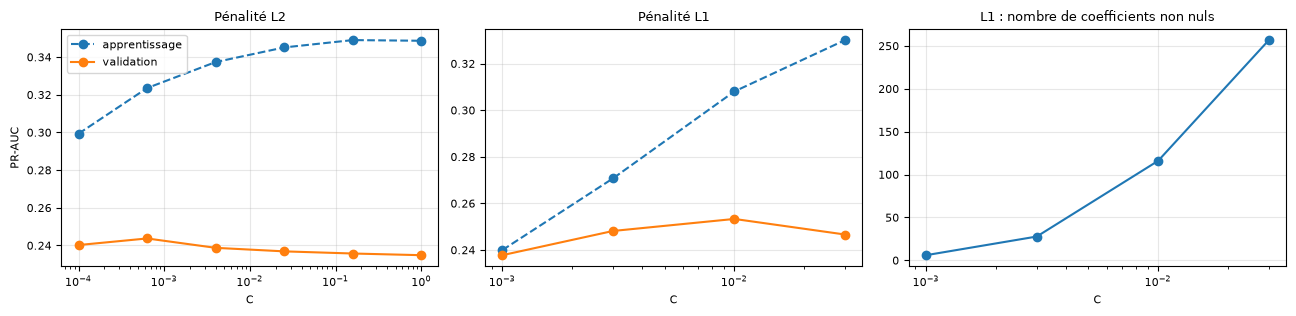

In [25]:
def reg_path():
    rows, r = [], np.random.default_rng(SEED)
    sub = [(np.sort(r.choice(tr, 45_000, replace=False)), va) for tr, va in CV_SPLITS]
    for pen, l1r, Cs in [("L2", 0.0, np.logspace(-4, 0, 6)), ("L1", 1.0, [0.001, 0.003, 0.01, 0.03])]:
        for C in Cs:
            for tr, va in sub:
                m = lr_pipe(C=C, l1_ratio=l1r).fit(XS[tr], S_y[tr])
                rows.append({"pénalité": pen, "C": C, "AP apprentissage": average_precision_score(S_y[tr], m.predict_proba(XS[tr])[:, 1]),
                             "AP validation": average_precision_score(S_y[va], m.predict_proba(XS[va])[:, 1]), "coef ≠ 0": int((m[-1].coef_ != 0).sum())})
    return pd.DataFrame(rows).groupby(["pénalité", "C"], as_index=False).mean()


path_df = cached("regpath_v1", reg_path)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for pen, g in path_df.groupby("pénalité"):
    ax[0 if pen == "L2" else 1].plot(g["C"], g["AP apprentissage"], "o--", label="apprentissage")
    ax[0 if pen == "L2" else 1].plot(g["C"], g["AP validation"], "o-", label="validation")
    ax[0 if pen == "L2" else 1].set_title(f"Pénalité {pen}"); ax[0 if pen == "L2" else 1].set_xscale("log"); ax[0 if pen == "L2" else 1].set_xlabel("C"); ax[0 if pen == "L2" else 1].grid(alpha=.3)
ax[0].set_ylabel("PR-AUC"); ax[0].legend()
g = path_df.query("`pénalité` == 'L1'"); ax[2].plot(g["C"], g["coef ≠ 0"], "o-"); ax[2].set_xscale("log"); ax[2].set_xlabel("C"); ax[2].set_title("L1 : nombre de coefficients non nuls"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Lecture.** Le modèle linéaire **sur-apprend** dès que la régularisation faiblit : l'écart entre le PR-AUC d'apprentissage (≈ 0,30-0,35) et de validation (≈ 0,24) est important. Le meilleur compromis est atteint pour une régularisation **forte** ($C\approx 6\cdot10^{-4}$ en L2, validation ≈ 0,244 ; $C=0{,}01$ en L1, validation ≈ 0,253 avec seulement ≈ 115 coefficients non nuls sur 551). La pénalité **L1 bat la L2** : sur des variables très redondantes (même signal à plusieurs échelles), choisir quelques variables vaut mieux que de répartir le poids sur toutes. C'est pourquoi le type de pénalité est ajouté à l'espace de recherche.

**Résultats de la recherche** pour les quatre combinaisons modèle × chaîne : meilleurs hyper-paramètres, score par défaut vs optimisé (mêmes folds), puis score du meilleur modèle avec **tout** l'apprentissage.

In [26]:
def best_model(model, selection):
    params = SEARCH[(model, selection)][1]
    return chain(model, selection).set_params(**params)


def tuning_row(model, selection):
    d = cv_eval(chain(model, selection), frac=1.0, splits=CV_SM)
    o = cv_eval(best_model(model, selection), frac=1.0, splits=CV_SM)
    f = cv_eval(best_model(model, selection), frac=1.0)
    row = {"modèle": {"LR": "Rég. logistique", "HGB": "HistGradientBoosting"}[model], "chaîne": "B (sélection ExtraTrees)" if selection else "A (551 variables)",
           "défaut (30 %)": d["PR-AUC"], "optimisé (30 %)": o["PR-AUC"], "optimisé (100 %)": f["PR-AUC"], "± folds": f["±"], "ROC-AUC (100 %)": f["ROC-AUC"]}
    print(row)
    return row


tuning = pd.DataFrame([cached(f"tuning_{m}_{'B' if s else 'A'}_{VER[m]}", lambda m=m, s=s: tuning_row(m, s)) for (m, s) in SEARCH])
for k, (_, p) in SEARCH.items():
    print(k, {a: (round(float(b), 4) if not hasattr(b, "get_params") else type(b).__name__) for a, b in p.items()})
tuning.round(3)

('LR', False) {'clf__C': 0.0047, 'clf__l1_ratio': 1.0, 'sc': 'QuantileTransformer'}
('LR', True) {'clf__C': 0.0649, 'clf__l1_ratio': 0.5, 'sc': 'StandardScaler', 'sel__max_features': 100.0}
('HGB', False) {'clf__l2_regularization': 0.0183, 'clf__learning_rate': 0.0693, 'clf__max_features': 0.3851, 'clf__max_iter': 184.0, 'clf__max_leaf_nodes': 19.0, 'clf__min_samples_leaf': 344.0}
('HGB', True) {'clf__l2_regularization': 1.3247, 'clf__learning_rate': 0.0394, 'clf__max_features': 0.42, 'clf__max_iter': 365.0, 'clf__max_leaf_nodes': 40.0, 'clf__min_samples_leaf': 51.0, 'sel__max_features': 200.0}


,modèle,chaîne,défaut (30 %),optimisé (30 %),optimisé (100 %),± folds,ROC-AUC (100 %)
0,Rég. logistique,A (551 variables),0.243,0.250,0.245,0.007,0.697
1,Rég. logistique,B (sélection ExtraTrees),0.254,0.255,0.252,0.013,0.701
2,HistGradientBoosting,A (551 variables),0.287,0.299,0.296,0.014,0.724
3,HistGradientBoosting,B (sélection ExtraTrees),0.270,0.297,0.297,0.018,0.725


**Lecture critique du tableau.**
* **Gain modeste mais réel pour le boosting sans sélection** (0,287 → 0,299 sur 30 % des données) ; **très net avec sélection** (0,270 → 0,297) car les valeurs par défaut étaient mal adaptées (taux d'apprentissage trop fort pour 200 variables) ; presque nul pour la régression logistique, déjà bien réglée par sa pénalité.
* **Plus de données n'améliore pas** (colonne « 100 % ») : les pixels voisins sont quasi identiques, donc 30 % de l'échantillon contient déjà l'essentiel de l'information. Les 100 % servent à vérifier que les réglages ne sont pas un artefact du sous-échantillonnage.
* **Avec sélection ≈ sans sélection après réglage** (0,297 contre 0,296 pour HGB ; 0,252 contre 0,245 pour la régression logistique) : la sélection n'améliore pas le score mais divise par 3 le nombre de variables. La comparaison *par défaut* (0,270 contre 0,287) aurait conduit à une conclusion **fausse** : il faut comparer les modèles chacun avec **ses** hyper-paramètres optimaux.
* Les écarts entre folds (± 0,01-0,02) sont **du même ordre que les gains** : les différences de 0,005 ne sont pas significatives.

## 11. Évaluation finale

**Protocole** (cf. section 3). Chaque modèle est **réajusté avec ses hyper-paramètres optimisés** sur *tous* les pixels échantillonnés du jeu d'entraînement (et non plus sur 30 %), puis évalué sur **tous les pixels** (prévalence réelle ≈ 1,2 %, probabilités corrigées du changement de prior) :
* **validation fixe** = fold 3 (entraînement : folds 0-2) → sert à **régler** ce qui reste (poids de l'ensemble, post-traitement) et à **choisir** le modèle ;
* **test** = fold 4 (entraînement : folds 0-3) → sert uniquement à **rapporter** les scores, une seule fois.

Modèles comparés : `HGB sur 19 variables brutes` (apport du feature engineering), `régression logistique` et `HistGradientBoosting`, chacun **sans sélection (A)** et **avec sélection (B)**, plus un **ensemble** régression logistique + boosting .

In [27]:
from scipy.ndimage import gaussian_filter
import joblib
SPECS = {
    "HGB, 19 brutes": (lambda: hgb_pipe(), RAW),
    "LR (A) 551 var.": (lambda: best_model("LR", False), ALL),
    "LR (B) sélection": (lambda: best_model("LR", True), ALL),
    "HGB (A) 551 var.": (lambda: best_model("HGB", False), ALL),
    "HGB (B) sélection": (lambda: best_model("HGB", True), ALL),
}
TRAIN_FOLDS = {3: [0, 1, 2], 4: [0, 1, 2, 3]}                # validation fixe / test
fold_rows = lambda f: np.flatnonzero(ROW_FOLD == f)


def predict_rows(model, rows, cols, chunk=150_000):
    out = np.empty(len(rows), np.float32)
    for i in range(0, len(rows), chunk):
        out[i:i + chunk] = prior_correct(model.predict_proba(get_rows(rows[i:i + chunk], cols))[:, 1])
    return out


def fit_model(name, f):
    """Ajuste le modèle `name` sur le jeu d'entraînement associé au fold d'évaluation f (zone tampon exclue) ; le modèle est sauvegardé sur disque."""
    path = PROC / f"model_{list(SPECS).index(name)}_{f}.joblib"
    if path.exists():
        return joblib.load(path)
    build, cols = SPECS[name]
    tr = np.flatnonzero(np.isin(S_fold, TRAIN_FOLDS[f]) & (ROW_DIST[f][S] > BUFFER))
    m = build().fit(XS[tr][:, cols], S_y[tr])
    joblib.dump(m, path)
    return m


def fit_predict(name, f):
    return predict_rows(fit_model(name, f), fold_rows(f), SPECS[name][1])


t0 = time.time()
PRED = {(name, f): cached(f"pred_{i}_{f}_v1", lambda n=name, f=f: fit_predict(n, f))
        for i, name in enumerate(SPECS) for f in (3, 4)}
print(f"prédictions sur tous les pixels des folds 3 et 4 : {time.time() - t0:.0f} s")

prédictions sur tous les pixels des folds 3 et 4 : 0 s


**Ensemble** . Moyenne pondérée des probabilités de la régression logistique et du boosting (chaîne A) ; le poids $w$ de la régression logistique est choisi **sur la validation** (fold 3).

In [28]:
def lab_scores(name_or_p, f):
    p = PRED[(name_or_p, f)] if isinstance(name_or_p, str) else name_or_p
    lab = ROW_Y[fold_rows(f)] >= 0
    return ROW_Y[fold_rows(f)][lab], p[lab]


W_GRID = [0.0, 0.1, 0.2, 0.3, 0.5]
ap_w = []
for w in W_GRID:
    y3, p3 = lab_scores(w * PRED[("LR (A) 551 var.", 3)] + (1 - w) * PRED[("HGB (A) 551 var.", 3)], 3)
    ap_w.append(average_precision_score(y3, p3))
W_ENS = W_GRID[int(np.argmax(ap_w))]
print("PR-AUC validation selon le poids de la régression logistique :", dict(zip(W_GRID, np.round(ap_w, 4).tolist())), "-> w =", W_ENS)
for f in (3, 4):
    PRED[("Ensemble LR + HGB (A)", f)] = W_ENS * PRED[("LR (A) 551 var.", f)] + (1 - W_ENS) * PRED[("HGB (A) 551 var.", f)]
NAMES = list(SPECS) + ["Ensemble LR + HGB (A)"]

PR-AUC validation selon le poids de la régression logistique : {0.0: 0.0605, 0.1: 0.0602, 0.2: 0.0594, 0.3: 0.058, 0.5: 0.0521} -> w = 0.0


**Post-traitement orienté DTI.** La métrique DTI additionne les probabilités sur *toute* la carte ($FP_w$) et pénalise 4 fois plus les oublis que les fausses alertes. Une probabilité bien calibrée (≈ 1 % presque partout) n'est donc **pas** la sortie qui maximise le DTI. On cherche, **sur la validation**, la transformation $p'=\mathrm{clip}\big(a\cdot(G_\sigma * p)^\gamma,\,0,\,1\big)$ : lissage gaussien $G_\sigma$ (les failles sont fines et les labels imprécis à ±3 pixels), puissance $\gamma$ et gain $a$. C'est une approche en deux temps : le modèle optimise une perte probabiliste, puis un post-traitement à 3 paramètres optimise la métrique réelle.

In [29]:
def to_map(p, rows):
    m = np.zeros(H * W, np.float32); m[VIDX[rows]] = p
    return m.reshape(H, W)


def post(pm, sigma, gamma, a):
    q = gaussian_filter(pm, sigma) if sigma > 0 else pm
    return np.clip(a * np.power(q, gamma), 0, 1).astype(np.float32)


EVAL = {f: DTI(Y, FOLD == f) for f in (3, 4)}
GRID = [(s, g, a) for s in (0, 1, 2, 3) for g in (0.5, 0.75, 1.0) for a in (1, 2, 4, 8, 16, 32, 64)]


def tune_post(name):
    pm = to_map(PRED[(name, 3)], fold_rows(3))
    sm = {s: (gaussian_filter(pm, s) if s > 0 else pm) for s in (0, 1, 2, 3)}
    res = {}
    for s, g, a in GRID:
        res[(s, g, a)] = EVAL[3](np.clip(a * np.power(sm[s], g), 0, 1).astype(np.float32))
    return res


t0 = time.time()
POST_VAL = {name: cached(f"post_{i}_v1", lambda n=name: tune_post(n)) for i, name in enumerate(NAMES)}
BEST_POST = {n: max(r, key=r.get) for n, r in POST_VAL.items()}
print(f"réglage du post-traitement : {time.time() - t0:.0f} s")
pd.DataFrame({n: {"(σ, γ, a) optimal": BEST_POST[n], "DTI validation": round(POST_VAL[n][BEST_POST[n]], 4),
                  "DTI validation sans post-traitement": round(POST_VAL[n][(0, 1.0, 1)], 4)} for n in NAMES}).T

réglage du post-traitement : 0 s


,"(σ, γ, a) optimal",DTI validation,DTI validation sans post-traitement
"HGB, 19 brutes","(0, 1.0, 32)",0.0925,0.015
LR (A) 551 var.,"(0, 1.0, 16)",0.0963,0.0239
LR (B) sélection,"(0, 1.0, 16)",0.0995,0.0274
HGB (A) 551 var.,"(0, 1.0, 16)",0.1159,0.0289
HGB (B) sélection,"(0, 1.0, 16)",0.1205,0.0273
Ensemble LR + HGB (A),"(0, 1.0, 16)",0.1159,0.0289


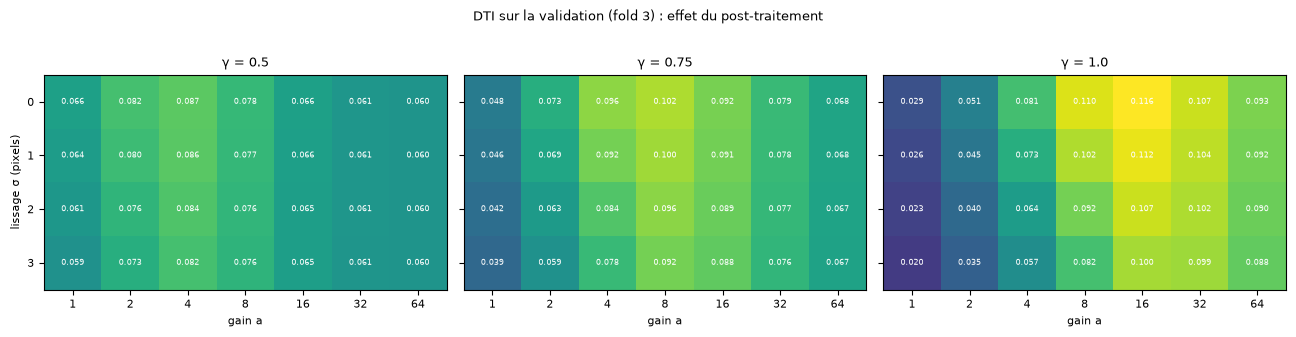

In [30]:
# sensibilité du DTI (validation, modèle HGB A) aux paramètres du post-traitement
r = POST_VAL["HGB (A) 551 var."]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a_, g in zip(ax, (0.5, 0.75, 1.0)):
    M = np.array([[r[(s, g, a)] for a in (1, 2, 4, 8, 16, 32, 64)] for s in (0, 1, 2, 3)])
    im = a_.imshow(M, cmap="viridis", vmin=0, vmax=max(v for v in r.values()), aspect="auto")
    a_.set_xticks(range(7), [1, 2, 4, 8, 16, 32, 64]); a_.set_yticks(range(4), [0, 1, 2, 3]); a_.set_xlabel("gain a"); a_.set_title(f"γ = {g}")
    for i in range(4):
        for j in range(7):
            a_.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=6, color="w")
ax[0].set_ylabel("lissage σ (pixels)"); fig.suptitle("DTI sur la validation (fold 3) : effet du post-traitement", y=1.03, fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.** Le post-traitement est **décisif** : sans lui, le DTI du boosting est ≈ 0,03 ; avec un gain $a=16$ (une probabilité de 6 % suffit à saturer à 1) il est multiplié par 4 (≈ 0,12 en validation). Deux enseignements : (i) il faut **sur-déclarer** car le DTI pénalise 4 fois plus un oubli qu'une fausse alerte ; (ii) le **lissage ne sert à rien** ($\sigma=0$ optimal) car la métrique pondère déjà les fausses alertes par la distance à une faille (tolérance de 3 pixels) ; la puissance $\gamma=1$ est aussi retenue. L'**ensemble** obtient $w=0$ : la régression logistique n'apporte aucune information que le boosting n'a pas déjà, l'ensemble se confond avec le boosting.

### Résultats sur le jeu de test (fold 4) et sur la validation (fold 3)
Tous les scores sont calculés sur **tous les pixels** du fold, avec le post-traitement choisi sur la validation. Le F1 / IoU sont pris au seuil qui maximise le F1 **sur la validation** ; le F1 tolérant compare les cartes binaires avec une tolérance de 3 pixels (comme la compétition).

In [31]:
def full_eval(name, f, thr):
    rows = fold_rows(f)
    p = PRED[(name, f)]
    y, pl = lab_scores(name, f)
    m = pixel_metrics(y, pl)
    pm = to_map(p, rows)
    s, g, a = BEST_POST[name]
    out = {"DTI brut": EVAL[f](np.clip(pm, 0, 1)), "DTI post-traité": EVAL[f](post(pm, s, g, a)),
           "PR-AUC": m["PR-AUC"], "ROC-AUC": m["ROC-AUC"], "log-loss": m["log-loss"]}
    pred_bin = pm > thr
    yb = (y == 1)
    out["F1 @seuil val."] = 2 * (pl[yb] > thr).sum() / max((pl > thr).sum() + yb.sum(), 1)
    out["F1 tolérant 3 px"] = tolerant_f1(pred_bin, Y, FOLD == f)[2]
    return out


THR = {n: pixel_metrics(*lab_scores(n, 3))["seuil F1 max"] for n in NAMES}
RES = cached("final_eval_v1", lambda: {(n, f): full_eval(n, f, THR[n]) for n in NAMES for f in (3, 4)})
final = pd.DataFrame({n: RES[(n, 4)] for n in NAMES}).T
final.insert(0, "PR-AUC (validation)", [RES[(n, 3)]["PR-AUC"] for n in NAMES])
final.insert(1, "DTI post-traité (validation)", [RES[(n, 3)]["DTI post-traité"] for n in NAMES])
print("TEST (fold 4) ; les deux premières colonnes sont les scores de validation (fold 3)")
final.round(3)

TEST (fold 4) ; les deux premières colonnes sont les scores de validation (fold 3)


,PR-AUC (validation),DTI post-traité (validation),DTI brut,DTI post-traité,PR-AUC,ROC-AUC,log-loss,F1 @seuil val.,F1 tolérant 3 px
"HGB, 19 brutes",0.028,0.093,0.020,0.082,0.029,0.651,0.063,0.059,0.234
LR (A) 551 var.,0.034,0.096,0.026,0.089,0.038,0.684,0.061,0.078,0.273
LR (B) sélection,0.046,0.099,0.025,0.086,0.038,0.678,0.062,0.078,0.213
HGB (A) 551 var.,0.060,0.116,0.026,0.099,0.046,0.701,0.061,0.110,0.273
HGB (B) sélection,0.058,0.121,0.025,0.102,0.047,0.709,0.061,0.112,0.312
Ensemble LR + HGB (A),0.060,0.116,0.026,0.099,0.046,0.701,0.061,0.110,0.273


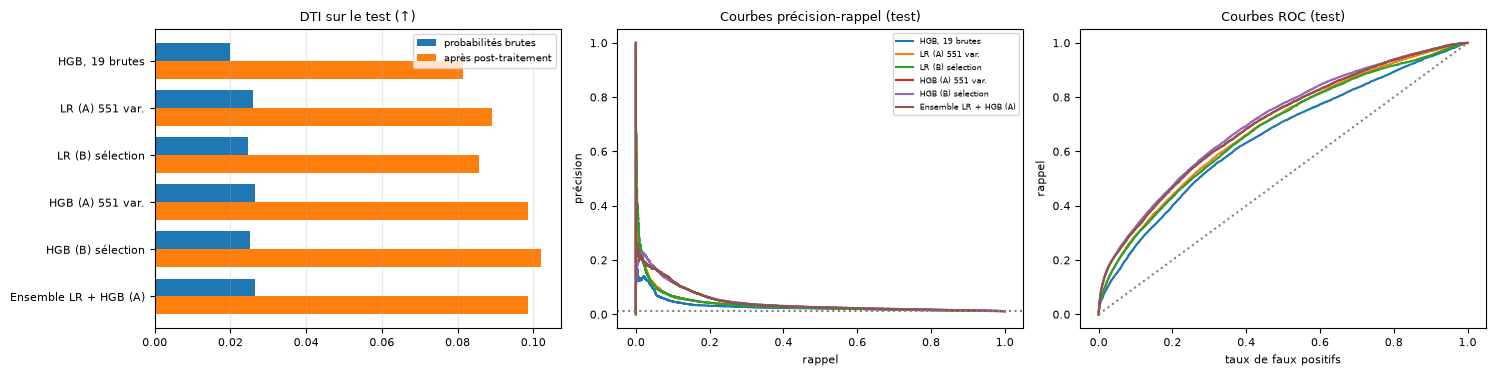

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
idx = np.arange(len(NAMES)); wd = 0.38
ax[0].barh(idx - wd / 2, final["DTI brut"], wd, label="probabilités brutes"); ax[0].barh(idx + wd / 2, final["DTI post-traité"], wd, label="après post-traitement")
ax[0].set_yticks(idx, NAMES); ax[0].invert_yaxis(); ax[0].set_title("DTI sur le test (↑)"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3, axis="x")
for name in NAMES:
    y, p = lab_scores(name, 4)
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=name)
    fp, tp, _ = roc_curve(y, p); ax[2].plot(fp, tp, label=name)
ax[1].axhline((y == 1).mean(), color="gray", ls=":"); ax[1].set_xlabel("rappel"); ax[1].set_ylabel("précision"); ax[1].set_title("Courbes précision-rappel (test)"); ax[1].legend(fontsize=6)
ax[2].plot([0, 1], [0, 1], color="gray", ls=":"); ax[2].set_xlabel("taux de faux positifs"); ax[2].set_ylabel("rappel"); ax[2].set_title("Courbes ROC (test)")
plt.tight_layout(); plt.show()

**Analyse des résultats (test, fold 4).**

| Question | Constat |
|---|---|
| **Le feature engineering aide-t-il ?** | Oui : HGB sur 19 variables brutes DTI **0,082** (PR-AUC 0,029) → sur 551 variables **0,099** (0,046) : +21 % de DTI, +60 % de PR-AUC. |
| **Sélection ou non ?** | Équivalent : HGB 200 variables **0,102** contre 551 variables 0,099 ; régression logistique 0,086 contre 0,089. Écarts dans le bruit (un seul bloc de test), mais la sélection divise par ~3 le nombre de variables à calculer. |
| **Linéaire ou boosting ?** | Le boosting gagne (0,099-0,102 contre 0,086-0,089) : il capture les effets de seuil / interactions (cf. dépendance partielle). |
| **La validation prédit-elle le test ?** | Le **classement** est conservé (HGB B > HGB A > LR > HGB brutes), mais les scores baissent (0,121 → 0,102 pour le meilleur) : la validation a servi à choisir le modèle et le post-traitement (biais optimiste) et les blocs de test sont simplement plus difficiles. |
| **Pourquoi des scores absolus faibles ?** | Labels incomplets (la base ne contient que des failles *connues*), cartes à 100 m pour des failles de quelques pixels, et prévalence de 1,2 % : ROC-AUC de seulement 0,68-0,71 pour les modèles à 551 variables. Le F1 tolérant ≈ 0,27-0,31 montre que le modèle localise surtout des **zones** de failles. |

*Remarque :* le F1 à seuil unique est instable (seuil choisi sur la validation, un seul bloc de test) ; on s'appuie donc surtout sur le DTI et la PR-AUC.

## 12. Interprétation

Le modèle retenu est choisi **sur la validation** (DTI post-traité du fold 3). On regarde ensuite ce qu'il a appris, avec plusieurs outils : cartes de prédiction et d'erreurs, **importance par permutation** (par groupes de variables, puis variable par variable), **coefficients** du modèle linéaire, **dépendance partielle** et **arbre peu profond**.

modèle retenu (meilleur DTI post-traité en validation) : HGB (B) sélection | post-traitement (σ, γ, a) = (0, 1.0, 16)
  validation : DTI 0.121 | test : DTI 0.102, PR-AUC 0.047


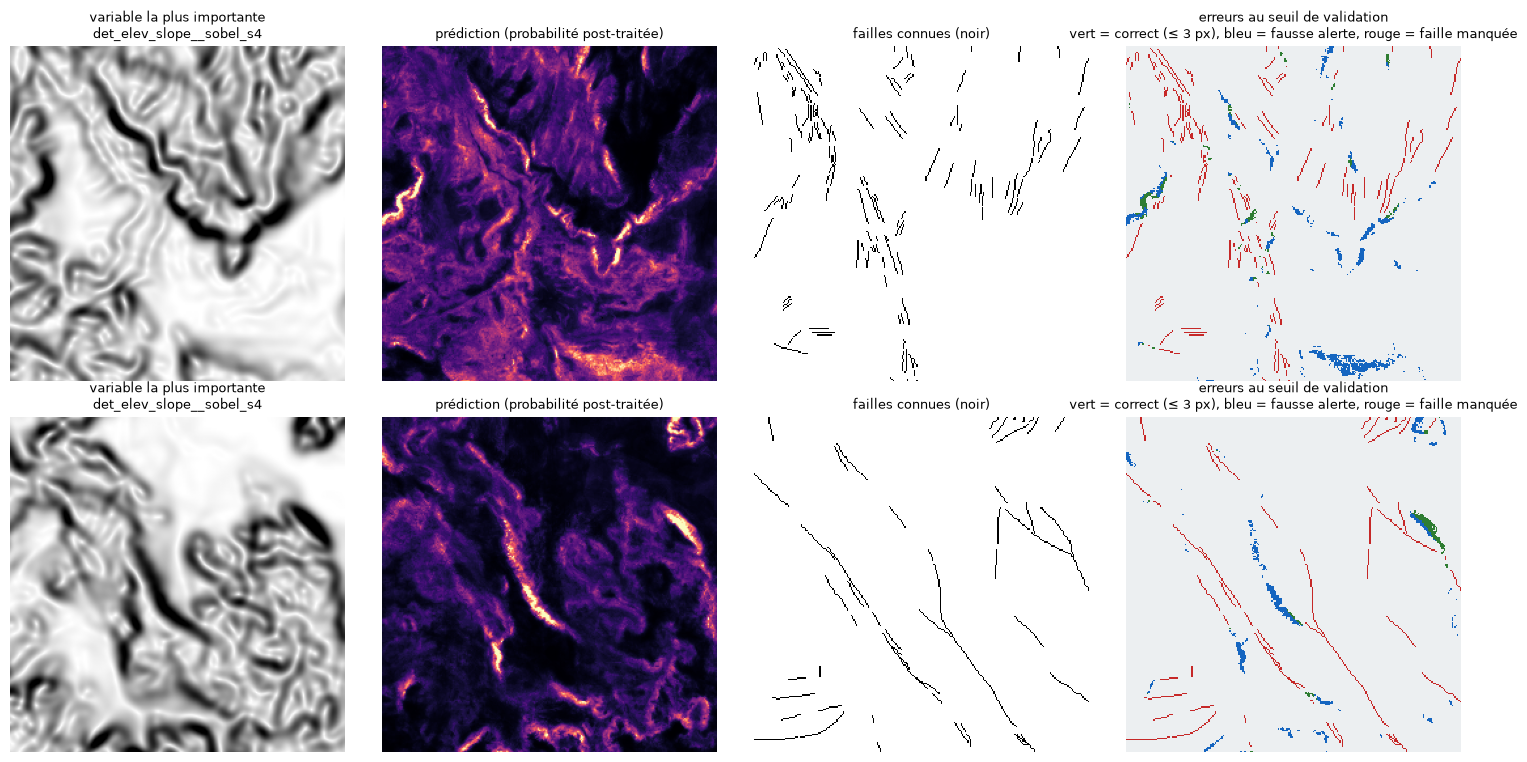

In [33]:
FINAL = max(NAMES, key=lambda n: POST_VAL[n][BEST_POST[n]])
print("modèle retenu (meilleur DTI post-traité en validation) :", FINAL, "| post-traitement (σ, γ, a) =", BEST_POST[FINAL])
print(f"  validation : DTI {RES[(FINAL, 3)]['DTI post-traité']:.3f} | test : DTI {RES[(FINAL, 4)]['DTI post-traité']:.3f}, PR-AUC {RES[(FINAL, 4)]['PR-AUC']:.3f}")

# deux blocs du fold de test les plus riches en failles
blocks = [b for b in np.argsort(-n_faults_blk) if fold_of_blk[b] == TEST_FOLD][:2]
pm_test = to_map(PRED[(FINAL, 4)], fold_rows(4))
pp_test = post(pm_test, *BEST_POST[FINAL])
best_feat = FEATURES[int(np.argmax(RANK["ExtraTrees"]))]
fmap = feature_map(best_feat)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for row, b in zip(axes, blocks):
    ys, xs = slice((b // nbc) * BLOCK, (b // nbc + 1) * BLOCK), slice((b % nbc) * BLOCK, (b % nbc + 1) * BLOCK)
    G = (Y[ys, xs] == 1); Pb = pm_test[ys, xs] > THR[FINAL]
    d_g, d_p = ndi.distance_transform_edt(~G), ndi.distance_transform_edt(~Pb)
    err = np.zeros(G.shape, np.int8)                       # 0 fond, 1 vrai positif, 2 faux positif, 3 faille manquée
    err[Pb & (d_g <= R_PX)] = 1; err[Pb & (d_g > R_PX)] = 2; err[G & (d_p > R_PX)] = 3
    lo, hi = np.nanpercentile(fmap[ys, xs], [2, 99])
    row[0].imshow(fmap[ys, xs], cmap="gray_r", vmin=lo, vmax=hi); row[0].set_title(f"variable la plus importante\n{best_feat}")
    row[1].imshow(pp_test[ys, xs], cmap="magma", vmin=0, vmax=1); row[1].set_title("prédiction (probabilité post-traitée)")
    row[2].imshow(np.where(VALID[ys, xs], 1 - G, np.nan), cmap="gray", vmin=0, vmax=1, interpolation="nearest"); row[2].set_title("failles connues (noir)")
    row[3].imshow(err, cmap=ListedColormap(["#eceff1", "#2e7d32", "#1565c0", "#c62828"]), vmin=0, vmax=3, interpolation="nearest")
    row[3].set_title("erreurs au seuil de validation\nvert = correct (≤ 3 px), bleu = fausse alerte, rouge = faille manquée")
    for a_ in row:
        a_.axis("off")
plt.tight_layout(); plt.show()

**Lecture des cartes.** Le modèle repère bien les **zones fracturées** (reliefs, escarpements) et place ses plus fortes probabilités le long de failles réelles (vert) ; mais il produit des **plages larges** de fausses alertes (bleu) et manque la plupart des traits fins (rouge). Une partie de ces « fausses alertes » est probablement de vraies failles **absentes de la base d'entraînement** (labels incomplets), ce qui pénalise injustement le score.

**Importance par permutation**. On mélange au hasard les valeurs d'une variable (ou d'un **groupe** de variables) sur des pixels de validation et on mesure la **baisse de PR-AUC** : plus elle est forte, plus le modèle s'appuie sur ce groupe. L'importance par groupe est la plus fiable ici : les variables d'un même groupe étant très corrélées (un même signal à plusieurs échelles), permuter une seule colonne est compensé par les autres et **sous-estime** son rôle.

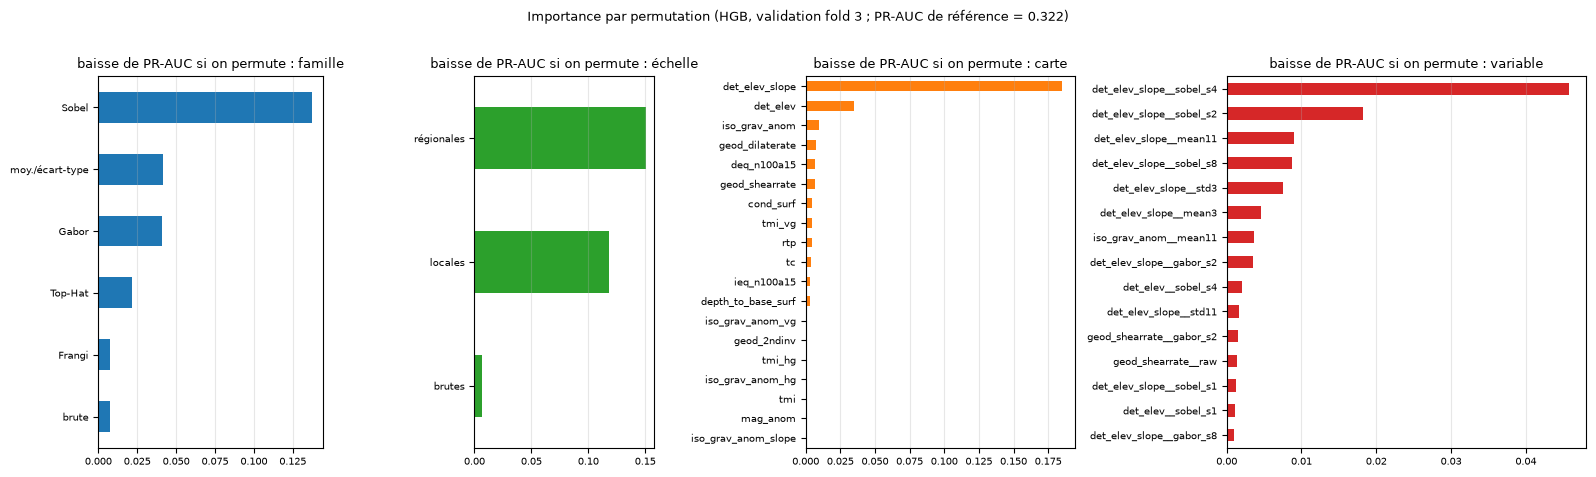

In [34]:
hgb_val = fit_model("HGB (A) 551 var.", 3)                         # modèle ajusté sur les folds 0-2
rng = np.random.default_rng(SEED)
sub = np.sort(rng.choice(np.flatnonzero(S_fold == 3), 30_000, replace=False))
Xv, yv = XS[sub], S_y[sub]
ap_base = average_precision_score(yv, hgb_val.predict_proba(Xv)[:, 1])


def perm_drop(cols, n_rep=3):
    drops = []
    for _ in range(n_rep):
        Xp = Xv.copy()
        Xp[:, cols] = Xv[np.ix_(rng.permutation(len(Xv)), cols)]
        drops.append(ap_base - average_precision_score(yv, hgb_val.predict_proba(Xp)[:, 1]))
    return float(np.mean(drops))


def permutation_importances():
    out = {"famille": {f: perm_drop(np.flatnonzero(FEAT_FAMILY == f)) for f in pd.unique(FEAT_FAMILY)},
           "échelle": {"brutes": perm_drop(RAW), "locales": perm_drop([i for i in LOCAL if i not in RAW]),
                       "régionales": perm_drop([i for i in REGIONAL if i not in RAW])},
           "carte": {b: perm_drop(np.flatnonzero(band_of == b)) for b in BAND_NAMES}}
    top = np.argsort(-RANK["ExtraTrees"])[:40]
    out["variable"] = {FEATURES[i]: perm_drop([i]) for i in top}
    return out


PERM = cached("perm_v1", permutation_importances)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, .8, 1.2, 1.6]})
for a_, key, col in zip(ax, ["famille", "échelle", "carte", "variable"], ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    s = pd.Series(PERM[key]).sort_values()
    if key == "variable":
        s = s.tail(15)
    s.plot.barh(ax=a_, color=col); a_.set_title(f"baisse de PR-AUC si on permute : {key}"); a_.tick_params(labelsize=7); a_.grid(alpha=.3, axis="x")
fig.suptitle(f"Importance par permutation (HGB, validation fold 3 ; PR-AUC de référence = {ap_base:.3f})", y=1.02, fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.** Le signal est dominé par la **topographie** : la carte `det_elev_slope` (pente du relief détendancé) pèse à elle seule le plus (≈ 0,18 de PR-AUC perdue si on la permute, sur 0,32), loin devant `det_elev` puis la gravimétrie et la géodésie. Côté filtres, la famille **Sobel** (contours) domine, suivie de moy./écart-type et Gabor ; **Top-Hat** pèse peu et **Frangi** presque rien, et les variables **brutes** seules comptent très peu : l'information utile n'est pas dans la valeur du pixel mais dans sa **variation locale**. Les échelles **régionales** (σ = 4-8, fenêtre 11) sont au moins aussi utiles que les échelles locales : une faille se voit par son contexte.

**Régression logistique : coefficients** (variables standardisées, donc comparables entre elles). Le signe indique le sens de l'effet sur la probabilité de faille.

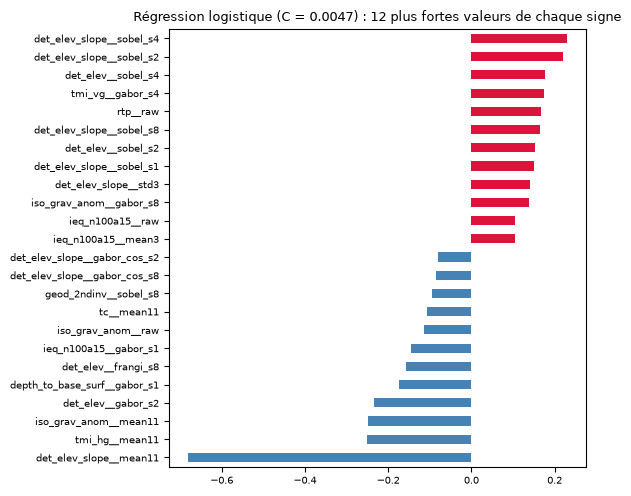

In [35]:
lr_val = fit_model("LR (A) 551 var.", 3)
coef = pd.Series(lr_val[-1].coef_[0], index=FEATURES).sort_values()
sel = pd.concat([coef.head(12), coef.tail(12)])
plt.figure(figsize=(6, 5)); sel.plot.barh(color=np.where(sel > 0, "crimson", "steelblue")); plt.title(f"Régression logistique (C = {lr_val[-1].C:.3g}) : 12 plus fortes valeurs de chaque signe"); plt.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Lecture.** La pénalité L1 ne garde qu'une partie des variables et les coefficients les plus forts confirment l'importance par permutation : Sobel de la pente (positif : un fort contraste topographique augmente la probabilité de faille). Le coefficient **négatif** de `det_elev_slope__mean11` est à lire *conditionnellement* aux autres variables (corrélées) : à contraste égal, une pente moyenne régionale élevée (grand relief montagneux) est moins associée aux failles cartographiées (hypothèse plausible, non vérifiée). Les coefficients sont donc **moins fiables à interpréter variable par variable** que les importances par groupe.

**Dépendance partielle** : effet moyen d'une variable sur la probabilité prédite, les autres variables étant moyennées. Variables : les 4 plus importantes par permutation individuelle.

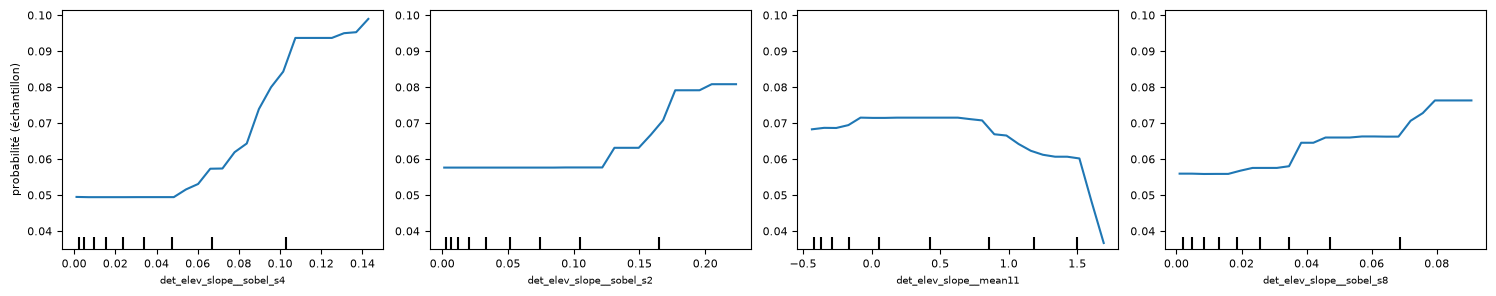

In [36]:
top4 = [FEATURES.index(n) for n in pd.Series(PERM["variable"]).sort_values().tail(4).index[::-1]]
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
PartialDependenceDisplay.from_estimator(hgb_val, Xv[:8000], top4, feature_names=FEATURES, kind="average", grid_resolution=25,
                                        response_method="predict_proba", ax=ax)
for a_ in ax:
    a_.set_ylabel(""); a_.xaxis.label.set_size(7)
ax[0].set_ylabel("probabilité (échantillon)")
plt.tight_layout(); plt.show()

**Lecture.** Les trois premières courbes sont **croissantes avec effet de seuil** : au-delà d'un contraste de pente (Sobel) la probabilité double environ (≈ 0,05 → 0,10). L'effet de la pente moyenne régionale est plat puis chute (à l'extrême droite, là où les données sont rares : à interpréter avec prudence). Ces relations sont **monotones et lisibles**, ce qui donne confiance dans le modèle (pas d'effet absurde).

**Arbre de décision peu profond** (profondeur 3) sur les 20 meilleures variables d'ExtraTrees : beaucoup moins précis que le boosting, mais il se lit en quelques secondes.

arbre de profondeur 3 : PR-AUC validation = 0.225 (HGB complet : 0.322 sur l'échantillon de validation)


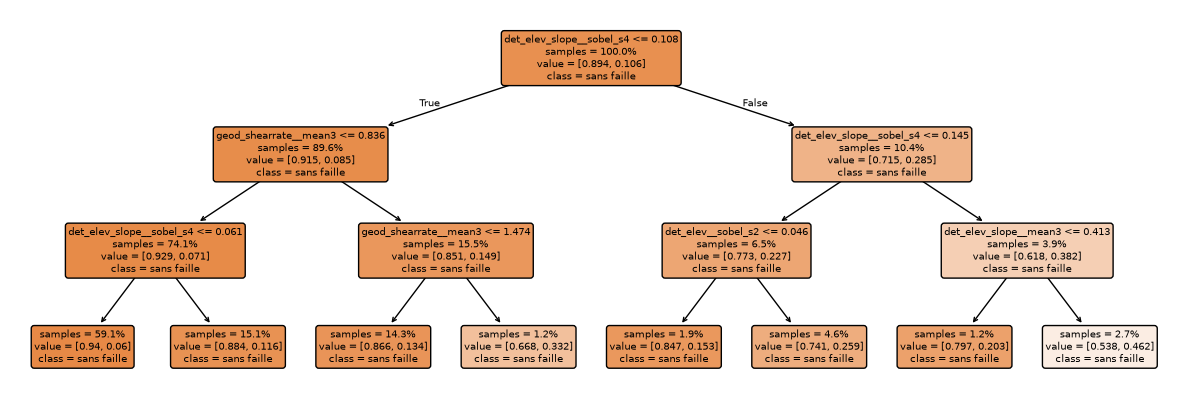

In [37]:
from sklearn.tree import plot_tree
top20 = np.argsort(-RANK["ExtraTrees"])[:20]
tr_i = np.flatnonzero(np.isin(S_fold, [0, 1, 2]) & (ROW_DIST[3][S] > BUFFER)); va_i = np.flatnonzero(S_fold == 3)
dt = Pipeline([("imp", SimpleImputer(strategy="median")),
               ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=2000, random_state=SEED))]).fit(XS[tr_i][:, top20], S_y[tr_i])
print(f"arbre de profondeur 3 : PR-AUC validation = {average_precision_score(S_y[va_i], dt.predict_proba(XS[va_i][:, top20])[:, 1]):.3f} (HGB complet : {ap_base:.3f} sur l'échantillon de validation)")
plt.figure(figsize=(15, 5))
plot_tree(dt[-1], feature_names=[FEATURES[i] for i in top20], class_names=["sans faille", "faille"], filled=True, impurity=False, proportion=True, fontsize=7, rounded=True)
plt.show()

**Lecture.** Un arbre de profondeur 3 atteint déjà **70 % du PR-AUC du boosting** (0,225 contre 0,322 sur l'échantillon de validation) : le critère dominant est `det_elev_slope__sobel_s4 > 0,108` (10 % des pixels), qui fait passer la part de failles de 6-12 % à 29-46 % (échantillon rééquilibré à 10,7 % de positifs). Le gain restant du boosting vient de l'accumulation de nombreuses petites interactions, difficiles à lire individuellement.

## 13. Verrous rencontrés et solutions

| # | Verrou | Symptôme / risque | Solution retenue |
|---|---|---|---|
| 1 | **Valeurs manquantes structurelles** | 58 % du rectangle est hors zone d'étude (`NaN` sur les 19 bandes) ; non imputable | Masque `VALID` ; métriques calculées uniquement sur les pixels étiquetés ; pour `mean`/`std` fenêtre **tronquée** (normalisée par le nombre de voisins valides), pour les autres filtres `NaN` rempli par le plus proche voisin valide |
| 2 | **Fort déséquilibre** | 1,2 % de pixels « faille » : l'exactitude et la ROC-AUC sont trompeuses | Métrique **PR-AUC** pour comparer, DTI pour la compétition ; **sous-échantillonnage** des négatifs (10 %) avec **correction du prior** des probabilités |
| 3 | **Fuite spatiale** | des pixels voisins sont quasi identiques : une validation croisée aléatoire est très optimiste | Découpage en **blocs de 256 px** (folds spatiaux), **zone tampon de 32 px** entre entraînement et évaluation, et **3 jeux disjoints** (entraînement / validation / test) |
| 4 | **Volumétrie** | 551 variables × 5,2 M pixels ≈ 11 Go : ne tient pas en mémoire de façon naïve | Calcul **parallèle** carte par carte, hypercube sur disque (`memmap`), prédiction **par paquets**, entraînement sur un échantillon, **caches** disque versionnés |
| 5 | **Explosion du banc de Gabor** | 8 angles × 4 échelles × 19 cartes = 608 colonnes quasi redondantes | **Résumé du banc** : réponse maximale + direction dominante $(\cos 2\varphi,\sin 2\varphi)$ (cyclique) à 2 échelles |
| 6 | **Échelles hétérogènes, queues lourdes** | Frangi / Gabor dépendent de l'amplitude ; distances jusqu'à 5·10⁶ | Normalisation robuste $\operatorname{arcsinh}((x-\text{médiane})/\sigma_{\text{rob}})$ avant filtrage |
| 7 | **La métrique n'est pas une perte** | le DTI additionne des probabilités sur toute la carte, pas dérivable proprement, les modèles optimisent la log-vraisemblance | Sélection / réglage sur la **PR-AUC** (CV), puis **post-traitement** $(\sigma,\gamma,a)$ réglé sur la validation : DTI ×4 |
| 8 | **Labels incomplets et imprécis** | « fausses alertes » qui sont peut-être de vraies failles non cartographiées ; décalages de quelques pixels | **F1 tolérant (3 px)** en plus des métriques par pixel ; lecture prudente des erreurs |
| 9 | **Modèle linéaire sous-régularisé** | la L2 seule sur-apprend (écart apprentissage / validation) | Chemin de régularisation, puis **type de pénalité** (L1 / elastic-net) ajouté à l'espace de recherche : L1 gagne (≈ 115 coefficients non nuls) |
| 10 | **Coût de la recherche d'hyper-paramètres** | 4 folds × plusieurs dizaines de candidats × sélection par forêt | `RandomizedSearchCV` sur 30 % de l'entraînement, `Pipeline(memory=...)` (sélection mise en cache), parallélisme, puis **vérification sur 100 %** des données |
| 11 | **Comparaison équitable avec / sans sélection** | à hyper-paramètres par défaut la sélection paraissait pénalisante (0,270 contre 0,287) | Chaque chaîne reçoit **ses** hyper-paramètres optimaux : l'écart disparaît (0,297 contre 0,299) |
| 12 | **Format de soumission** | le masque `NaN` du GeoTIFF doit coïncider avec celui de l'exemple | Masque = pixels étiquetés (vérifié identique) ; 3 061 pixels étiquetés sans donnée d'entrée prédits à 0 |
| 13 | **Énoncé vs données** | l'énoncé annonce 3292 × 3730 ; le raster est de 3730 lignes × 3292 colonnes | Dimensions vérifiées à la lecture ; la grille de la soumission est comparée à celle de l'exemple |
| 14 | **Reproductibilité** | calculs de plusieurs heures | graine fixée (`SEED`), caches versionnés dans `data/processed/` (ignoré par git) ; le notebook se relance en quelques minutes une fois les caches présents |

## 14. Analyse critique

### Bilan chiffré

| Choix | Effet mesuré | Où |
|---|---|---|
| **Feature engineering** (19 → 551 variables) | PR-AUC CV 0,185 → 0,288 (boosting) ; test : DTI 0,082 → 0,099 | §6, §11 |
| **Filtres les plus utiles** | Sobel (1er en ablation comme en permutation), puis moy./écart-type, Gabor, Top-Hat ; **Frangi quasi inutile** (+0,017 seul). Forte redondance : retirer une famille coûte < 0,01 | §7, §12 |
| **Sélection de variables** | ≈ neutre après réglage (0,297 contre 0,296 en CV ; test 0,102 contre 0,099), mais 200 variables au lieu de 551 | §8, §10, §11 |
| **Hyper-paramètres** | boosting : +0,012 à +0,027 (taux d'apprentissage dominant) ; linéaire : +0,001 à +0,007 (pénalité L1) | §10 |
| **Famille de modèle** | arbres en ensemble ≫ linéaire > MLP > arbre > Naive Bayes ; ensemble linéaire + boosting : poids 0 | §9, §11 |
| **Post-traitement DTI** | DTI ×3 à ×4 (gain $a=16$, pas de lissage) | §11 |
| **Modèle retenu** (choisi sur la validation) | HGB avec sélection ExtraTrees (200 variables) : **DTI test 0,102** | §11 |

### Limites (honnêteté sur ce que valent ces chiffres)
1. **Un seul bloc de test.** Pas d'intervalle de confiance : les écarts de 0,003 entre modèles ne sont pas significatifs. De plus le score chute de 0,121 (validation) à 0,102 (test) : les blocs diffèrent par leur géologie et le choix du modèle / post-traitement sur la validation est légèrement optimiste.
2. **Valeurs absolues de la CV optimistes.** Les PR-AUC de CV (≈ 0,29) sont calculées sur un échantillon à 10,7 % de positifs ; sur les vrais pixels (1,2 %) la PR-AUC est ≈ 0,05. Les **comparaisons** entre modèles restent valides (même échantillon, mêmes folds), pas les valeurs absolues.
3. **Labels = failles *connues*.** La base est incomplète et en partie dérivée de la topographie : le modèle apprend « où les escarpements ressemblent à des failles cartographiées » (`det_elev_slope` domine). Il est possible qu'il généralise moins bien à des failles inconnues, qui sont le vrai but de la compétition.
4. **Pixels traités indépendamment.** Le contexte spatial n'est transmis que par les filtres ; le modèle ne force pas la continuité des failles. Les cartes montrent des **plages** de probabilité plutôt que des traits fins (F1 tolérant ≈ 0,3).
5. **Normalisation transductive.** La médiane et l'écart robuste de la normalisation sont estimés sur toute la carte (sans jamais utiliser les labels) : il n'y a pas de fuite de la cible, mais le protocole n'est pas strictement inductif.
6. **Interprétation.** Les variables de l'hypercube sont très corrélées : seules les importances **par groupe** sont fiables ; les coefficients individuels et la permutation d'une seule variable sont à nuancer.

### Perspectives
* **Réseau convolutif (U-Net)** apprenant directement les filtres et la continuité spatiale, au prix de beaucoup plus de calcul.
* **Post-traitement morphologique** (squelettisation, filtrage des composantes trop petites) pour obtenir des traits fins.
* **Réduire l'hypercube** : abandonner Frangi, garder Sobel multi-échelle, moyenne / écart-type régionaux et topographie.
* **Validation plus robuste** : plusieurs blocs de test (validation croisée spatiale imbriquée) pour obtenir des intervalles de confiance.

## 15. Soumission et conclusion

Le modèle retenu en validation est **réajusté sur tous les folds** (0 à 4, sans zone tampon puisqu'il n'y a plus de validation) puis appliqué à **tous les pixels de la zone d'étude** ; le post-traitement choisi sur la validation est appliqué à la carte de probabilités. Format demandé par la compétition : GeoTIFF mono-bande `float32`, valeurs dans [0, 1], même grille que les entrées, `NaN` là où l'exemple fourni est `NaN` (pixels non étiquetés).

carte finale calculée en 0 s ; valeurs dans [0.000, 1.000], moyenne 0.1551


même grille que l'exemple fourni : True | même masque NaN : True


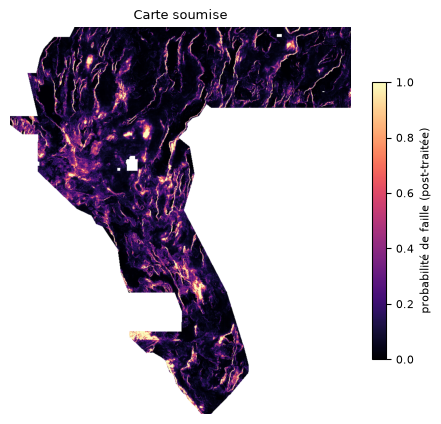

In [38]:
COMPONENTS = [("LR (A) 551 var.", W_ENS), ("HGB (A) 551 var.", 1 - W_ENS)] if FINAL.startswith("Ensemble") else [(FINAL, 1.0)]


def final_map():
    p = np.zeros(N, np.float32)
    for name, w in COMPONENTS:
        build, cols = SPECS[name]
        m = build().fit(XS[:, cols], S_y)
        p += w * predict_rows(m, np.arange(N), cols)
    return p


t0 = time.time()
p_all = cached("final_probs_v1", final_map)
pm_all = np.zeros(H * W, np.float32); pm_all[VIDX] = p_all
sub_map = post(pm_all.reshape(H, W), *BEST_POST[FINAL])
sub_map[Y < 0] = np.nan                          # le masque de l'exemple fourni = pixels étiquetés (Y >= 0)
sub_map[(Y >= 0) & ~VALID] = 0.0                  # quelques pixels étiquetés sans aucune donnée d'entrée : pas de signal, on prédit 0
print(f"carte finale calculée en {time.time() - t0:.0f} s ; valeurs dans [{np.nanmin(sub_map):.3f}, {np.nanmax(sub_map):.3f}], moyenne {np.nanmean(sub_map):.4f}")

out_path = ROOT / "submissions" / "submission.tif"
out_path.parent.mkdir(exist_ok=True)
prof = PROFILE.copy(); prof.update(dtype="float32", count=1, nodata=np.nan, compress="lzw")
with rasterio.open(out_path, "w", **prof) as dst:
    dst.write(sub_map.astype(np.float32), 1)
with rasterio.open(ROOT / "data" / "raw" / "example_submission.tif") as ex, rasterio.open(out_path) as got:
    print("même grille que l'exemple fourni :", ex.shape == got.shape and ex.transform == got.transform and ex.crs == got.crs,
          "| même masque NaN :", bool((np.isnan(ex.read(1)) == np.isnan(got.read(1))).all()))

plt.figure(figsize=(5.5, 6)); plt.imshow(sub_map[::4, ::4], cmap="magma", vmin=0, vmax=1)
plt.colorbar(shrink=.6, label="probabilité de faille (post-traitée)"); plt.title("Carte soumise"); plt.axis("off"); plt.show()

**Carte soumise.** `submissions/submission.tif` : probabilité de faille post-traitée, mêmes grille et masque que l'exemple fourni.

### Conclusion
* **Verrous** : valeurs manquantes structurelles, déséquilibre, fuite spatiale, volumétrie, métrique non dérivable, labels incomplets (§13).
* **Mise en forme des données** : 19 cartes → hypercube de **551 variables par pixel** (brut, moyenne / écart-type 3×3 et 11×11, Sobel, Gabor, Frangi, Top-Hat à σ = 1, 2, 4, 8). Il fait passer le DTI de test de 0,082 à 0,099 ; la sélection de variables (ExtraTrees, 200 variables) est **neutre sur le score** mais divise le nombre de variables par ≈ 3.
* **Hyper-paramètres** : `RandomizedSearchCV` dans un `Pipeline` ; le **taux d'apprentissage** du boosting domine, la pénalité **L1** est la meilleure pour le modèle linéaire ; comparer les modèles chacun avec **ses** réglages optimaux change les conclusions.
* **Résultat** : `HistGradientBoosting` + sélection + post-traitement $(\sigma=0,\gamma=1,a=16)$ : **DTI test = 0,102**, choisi sur la validation. Les modèles se fondent surtout sur le **contraste de pente topographique** (Sobel à σ = 2-8).
* **Regard critique** : un seul bloc de test, labels incomplets et dérivés du relief, pixels traités indépendamment ; les perspectives (U-Net, post-traitement morphologique) sont décrites en §14.